# Layer 2: decision-making bias (RQ2)

**RQ2** asks whether players bypass better maximal-VAEP options that they could see. Layer 1 (`01_layer1_visual_constraint.ipynb`) established which teammates a passer could realistically see and answered RQ1. This notebook asks a different question: **among the teammates a player could see, how often did they bypass a genuinely better option?**

Answering that fairly needs "visible teammates" narrowed down to teammates who were also **legitimate** alternatives: onside, and not unrealistically difficult to reach. This notebook adds those filters and then computes the bypass rate specified in the proposal (Section 4.5.2):

1. **Offside detection** from the defender positions in the 360 freeze frame.
2. **xP (expected pass completion probability)**, from pass distance, the nearest defender and defender density near the target.
3. **Maximal-VAEP options**, using Karun Singh's public xT grid: a candidate whose target zone has higher expected threat than the passer's zone, and whose VAEP value is higher than the pass actually made.

The vision-cone functions (`src/vision_cone.py`), the trained VAEP models and the candidate values from Layer 1 are loaded from disk, not rebuilt.

In [1]:
# shared figure settings used in every notebook:
# colours (navy, green, grey and light blue) and one folder for every saved figure
import matplotlib.pyplot as plt
from cycler import cycler
from pathlib import Path
plt.rcParams['axes.prop_cycle'] = cycler(color=['#1E2761', '#2C5F2D', '#9AA0A6', '#7F8FC0'])

FIGURES = Path('../data/results/figures')
FIGURES.mkdir(parents=True, exist_ok=True)


def save_fig(fig, name):
    """Save a figure to the shared figures folder, in the same format in every notebook."""
    fig.savefig(FIGURES / name, dpi=200, bbox_inches='tight', facecolor='white')
    print(f"saved {FIGURES / name}")


import os
os.environ["SBOPENDATAPATH"] = r"C:\Users\raees\Documents\Honours\My Research\Code\open-data\data"

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
from mplsoccer import Pitch
import sys
sys.path.append('..')

from src.vision_cone import angle_to_teammate

import socceraction.xthreat as xthreat
xT_model = xthreat.load_model("https://karun.in/blog/data/open_xt_12x8_v1.json")

# reload everything already computed in notebook 1, no need to recompute
cf_valid = pd.read_pickle('../data/results/rq1_counterfactual_comparison.pkl')
cf_valid_all3 = pd.read_pickle('../data/results/rq1_counterfactual_comparison_all3_fixed.pkl')

## 1. Offside detection from the 360 freeze frame

A candidate teammate is offside if they are closer to the opponent's goal line than both the ball and the second-deepest defender at that moment. The goalkeeper is included in that ordering, not excluded (they are usually deepest, but not always).

To know which end each team attacks, the opposing goalkeeper's position is used, which the freeze frame marks with the `keeper` flag. Where the opposing keeper stands shows which goal the passer's team is attacking.

In [3]:
from src.vision_cone import add_orientation_vectors, build_pass_visibility_table
from statsbombpy import sb
import pandas as pd
import time
from pathlib import Path

CACHE_DIR = Path("../data/statsbomb_cache")
CACHE_DIR.mkdir(parents=True, exist_ok=True)

def cached_events(match_id, retries=5, backoff=5):
    cache_file = CACHE_DIR / f"events_{match_id}.pkl"
    if cache_file.exists():
        return pd.read_pickle(cache_file)
    for attempt in range(retries):
        try:
            events = sb.events(match_id=match_id)
            events.to_pickle(cache_file)
            return events
        except Exception as e:
            if attempt == retries - 1:
                raise
            wait = backoff * (attempt + 1)
            print(f"events fetch failed ({e}), retrying in {wait}s...")
            time.sleep(wait)

def cached_frames(match_id, retries=5, backoff=5):
    cache_file = CACHE_DIR / f"frames_{match_id}.pkl"
    if cache_file.exists():
        return pd.read_pickle(cache_file)
    for attempt in range(retries):
        try:
            frames = sb.frames(match_id=match_id, fmt='dataframe')
            frames.to_pickle(cache_file)
            return frames
        except Exception as e:
            if attempt == retries - 1:
                raise
            wait = backoff * (attempt + 1)
            print(f"frames fetch failed ({e}), retrying in {wait}s...")
            time.sleep(wait)

sample_match_id = "3943043"  # reuse the Euro 2024 final
m_events = cached_events(sample_match_id)
m_events_oriented = add_orientation_vectors(m_events)
m_frames = cached_frames(sample_match_id)

sample_pass_events = m_events_oriented[
    (m_events_oriented['type'] == 'Pass') &
    (m_events_oriented['orientation_vector'].notna())
]
sample = sample_pass_events.iloc[50]
event_id = sample['id']

frame = m_frames[m_frames['id'] == event_id]
opponent_keeper = frame[(frame['teammate'] == False) & (frame['keeper'] == True)]

print(f"Opponent keeper found in this frame: {not opponent_keeper.empty}")
if not opponent_keeper.empty:
    print(f"Opponent keeper location: {opponent_keeper.iloc[0]['location']}")
print(f"Passer location: {sample['location']}")

Opponent keeper found in this frame: True
Opponent keeper location: [115.6168082840095, 43.25187666650353]
Passer location: [92.4, 23.2]


saved ..\data\results\figures\rq2_attacking_direction_check.png


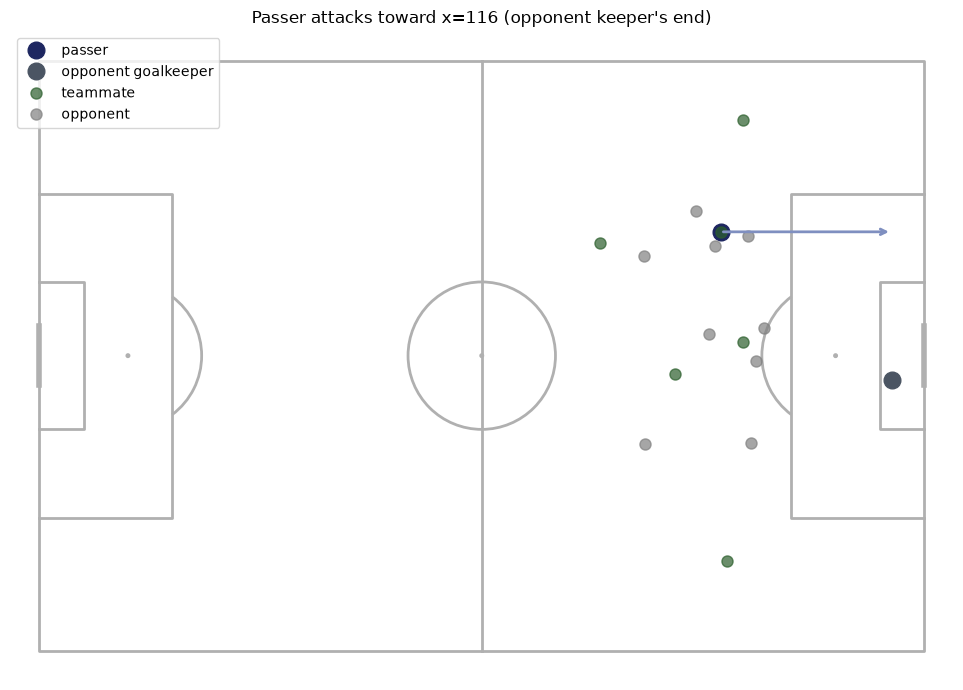

In [4]:
pitch = Pitch(pitch_type='statsbomb')
fig, ax = pitch.draw(figsize=(10, 7))

passer_loc = sample['location']
keeper_loc = opponent_keeper.iloc[0]['location']

# passer
ax.plot(passer_loc[0], passer_loc[1], 'o', color='#1E2761', markersize=12, label='passer')

# opponent goalkeeper
ax.plot(keeper_loc[0], keeper_loc[1], 'o', color='#4B5563', markersize=12, label='opponent goalkeeper')

# all other players in the frame, for context
others = frame[
    (frame['id'] == event_id) &
    ~((frame['teammate'] == False) & (frame['keeper'] == True))
]

teammates_plotted = False
opponents_plotted = False

for _, row in others.iterrows():
    loc = row['location']
    if row['teammate']:
        label = 'teammate' if not teammates_plotted else None
        ax.plot(loc[0], loc[1], 'o', color='#2C5F2D', markersize=8, alpha=0.7, label=label)
        teammates_plotted = True
    else:
        label = 'opponent' if not opponents_plotted else None
        ax.plot(loc[0], loc[1], 'o', color='grey', markersize=8, alpha=0.7, label=label)
        opponents_plotted = True

# arrow showing implied attacking direction: passer toward keeper's end
attacking_toward_x = keeper_loc[0]
ax.annotate('', xy=(min(attacking_toward_x, 118), passer_loc[1]), xytext=(passer_loc[0], passer_loc[1]),
            arrowprops=dict(arrowstyle='->', color='#7F8FC0', lw=2))

ax.legend(loc='upper left')
ax.set_title(f"Passer attacks toward x={attacking_toward_x:.0f} (opponent keeper's end)")
save_fig(fig, 'rq2_attacking_direction_check.png')
plt.show()

### The offside line for this pass

The offside line is the position of the second-deepest opponent, ordered by closeness to their own goal line, goalkeeper included. If the opposing keeper is near x = 120, the defending team's goal is at x = 120, so "deepest" means highest x.

A candidate is offside if their x position is beyond both the ball and the offside line, on the attacking side. A candidate in their own half (the near side of the halfway line, x = 60) is never offside, whatever the line. This is a separate rule in the laws of the game and is checked first.

In [5]:
def compute_offside_line(frame_at_event, attacking_toward_x):
    """
    Given all players in a 360 frame and the x-coordinate the attacking team
    is attacking toward, return the offside line x-coordinate: the position
    of the second-deepest defender, goalkeeper included in the sort when
    visible in this frame. When the goalkeeper is not visible in this frame
    (StatsBomb 360's known camera blind spot), the deepest visible outfield
    defender is used instead, since the goalkeeper is almost always deeper
    than every outfield defender during open play, so this approximates the
    true second-to-last-defender position rather than defaulting to the
    second-deepest outfield player, which is too shallow and over-flags
    players as offside.
    """
    defenders = frame_at_event[frame_at_event['teammate'] == False].copy()
    if len(defenders) < 1:
        return None

    defenders['x'] = defenders['location'].apply(lambda loc: loc[0])
    keeper_visible = defenders['keeper'].any()

    if attacking_toward_x > 60:
        sorted_defenders = defenders.sort_values('x', ascending=False)
    else:
        sorted_defenders = defenders.sort_values('x', ascending=True)

    if keeper_visible:
        if len(sorted_defenders) < 2:
            return None
        return sorted_defenders.iloc[1]['x']
    else:
        return sorted_defenders.iloc[0]['x']

In [6]:
HALFWAY_X = 60  # StatsBomb pitch is 120 units long, halfway is at x=60

def is_offside(candidate_x, ball_x, offside_line_x, attacking_toward_x):
    if offside_line_x is None:
        return False
    if attacking_toward_x > 60:
        if candidate_x < HALFWAY_X:  # still in own half, cannot be offside
            return False
        return candidate_x > ball_x and candidate_x > offside_line_x
    else:
        if candidate_x > HALFWAY_X:  # still in own half, cannot be offside
            return False
        return candidate_x < ball_x and candidate_x < offside_line_x

In [7]:
# scan a handful of passes in this match looking for a genuine offside case
for idx in range(0, 200):
    test_sample = sample_pass_events.iloc[idx]
    test_event_id = test_sample['id']
    test_frame_data = m_frames[m_frames['id'] == test_event_id]

    test_keeper = test_frame_data[(test_frame_data['teammate'] == False) & (test_frame_data['keeper'] == True)]
    if test_keeper.empty:
        continue

    test_attacking_toward_x = test_keeper.iloc[0]['location'][0]
    test_offside_line = compute_offside_line(test_frame_data, test_attacking_toward_x)
    if test_offside_line is None:
        continue

    test_ball_x = test_sample['location'][0]
    test_teammates = test_frame_data[test_frame_data['teammate'] == True]

    for _, row in test_teammates.iterrows():
        tx = row['location'][0]
        if is_offside(tx, test_ball_x, test_offside_line, test_attacking_toward_x):
            print(f"Found offside candidate at pass index {idx}, event_id {test_event_id}")
            print(f"  Candidate x={tx:.2f}, offside line={test_offside_line:.2f}, ball x={test_ball_x:.2f}")
            break

Found offside candidate at pass index 78, event_id dd7c66d5-69c1-48dc-b931-204ba90f0a70
  Candidate x=110.25, offside line=109.80, ball x=106.50
Found offside candidate at pass index 158, event_id a8241a9b-b73e-4f83-8506-8895c29647c1
  Candidate x=112.51, offside line=109.82, ball x=100.20
Found offside candidate at pass index 187, event_id e02750b9-17cb-4509-bfed-0bea551126bf
  Candidate x=104.35, offside line=103.35, ball x=81.00
Found offside candidate at pass index 189, event_id 81c1c2ec-9c0b-4cae-90f8-09c5e0c358d2
  Candidate x=105.33, offside line=104.16, ball x=90.10
Found offside candidate at pass index 190, event_id f3f38929-16fa-412d-950b-096b105dd69f
  Candidate x=99.92, offside line=99.60, ball x=80.40


saved ..\data\results\figures\rq2_offside_line_example.png


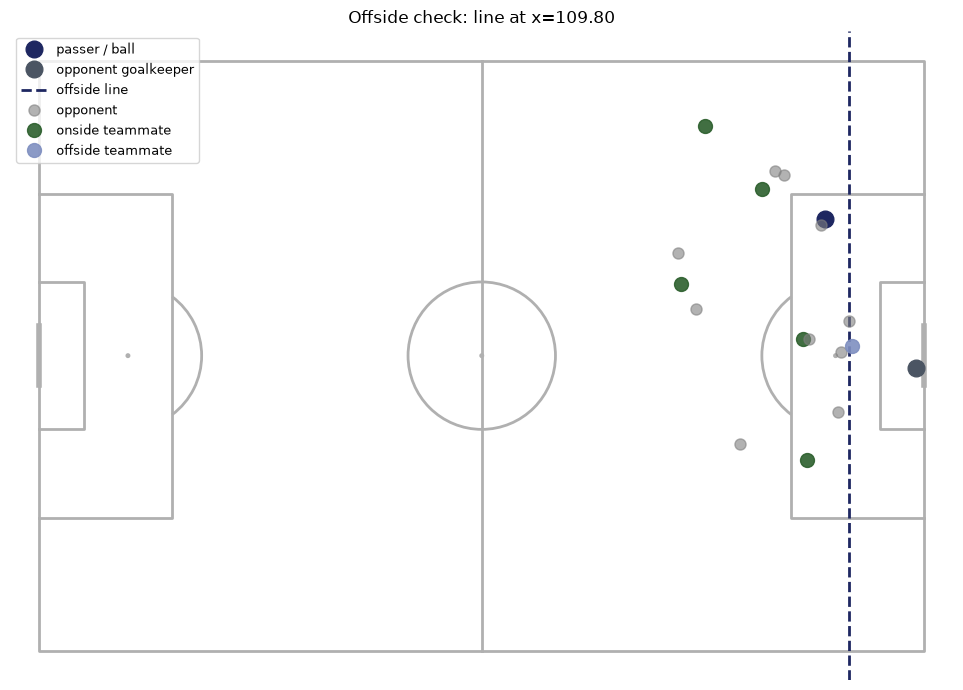

In [8]:
test_event_id = "dd7c66d5-69c1-48dc-b931-204ba90f0a70"
test_sample = sample_pass_events[sample_pass_events['id'] == test_event_id].iloc[0]
test_frame_data = m_frames[m_frames['id'] == test_event_id]

test_keeper = test_frame_data[(test_frame_data['teammate'] == False) & (test_frame_data['keeper'] == True)]
test_attacking_toward_x = test_keeper.iloc[0]['location'][0]
test_offside_line = compute_offside_line(test_frame_data, test_attacking_toward_x)
test_ball_loc = test_sample['location']

pitch = Pitch(pitch_type='statsbomb')
fig, ax = pitch.draw(figsize=(10, 7))

# ball / passer
ax.plot(test_ball_loc[0], test_ball_loc[1], 'o', color='#1E2761', markersize=12, label='passer / ball')

# opponent keeper
ax.plot(test_keeper.iloc[0]['location'][0], test_keeper.iloc[0]['location'][1],
        'o', color='#4B5563', markersize=12, label='opponent goalkeeper')

# offside line, drawn vertically across the pitch
ax.axvline(test_offside_line, color='#1E2761', linestyle='--', linewidth=2, label='offside line')

# all other players
teammates_plotted, opponents_plotted = False, False
for _, row in test_frame_data.iterrows():
    if row.get('actor', False):
        continue
    loc = row['location']
    if row['teammate']:
        tx = loc[0]
        is_off = is_offside(tx, test_ball_loc[0], test_offside_line, test_attacking_toward_x)
        color = '#7F8FC0' if is_off else '#2C5F2D'
        label = ('offside teammate' if is_off else 'onside teammate')
        ax.plot(loc[0], loc[1], 'o', color=color, markersize=10, alpha=0.9,
                label=label if (is_off or not teammates_plotted) else None)
        teammates_plotted = True
    else:
        if row.get('keeper', False):
            continue
        label = 'opponent' if not opponents_plotted else None
        ax.plot(loc[0], loc[1], 'o', color='grey', markersize=8, alpha=0.6, label=label)
        opponents_plotted = True

ax.legend(loc='upper left', fontsize=9)
ax.set_title(f"Offside check: line at x={test_offside_line:.2f}")
save_fig(fig, 'rq2_offside_line_example.png')
plt.show()

In [9]:
from src.offside import classify_offside

# re-run your positive-case example using the packaged version
test_result = classify_offside(test_frame_data, test_ball_loc)
print(test_result[['location', 'attacking_toward_x', 'offside']])

                                      location  attacking_toward_x  offside
5157   [86.98170306169067, 30.330890071052735]           118.92478    False
5159    [90.29616167172878, 8.853739984723603]           118.92478    False
5161   [98.01765786485447, 17.398890401235548]           118.92478    False
5164   [103.57368170361602, 37.71423300958111]           118.92478    False
5165   [104.08121642159668, 54.15448454050586]           118.92478    False
5168               [106.5, 21.399999618530273]           118.92478    False
5172  [110.25204370788717, 38.674589868141815]           118.92478     True


## 2. Expected pass completion (xP)

As in the proposal (Section 2.3.1), xP is a logistic regression on pass distance, the distance from the target to the nearest defender, and the density of defenders around the target. Unlike xT, there is no public trained model, so it is trained on this data, like VAEP.

- **Label:** whether a real pass was completed (`result_name`).
- **Features:** computed from the passer's location, the target location and the defender positions in the same freeze frame.

In [10]:
def compute_xp_features(passer_loc, target_loc, frame_at_event):
    """
    Compute distance, angle-to-nearest-defender, and defender density
    features for a pass from passer_loc to target_loc, given the 360 frame.
    """
    dx = target_loc[0] - passer_loc[0]
    dy = target_loc[1] - passer_loc[1]
    pass_distance = np.sqrt(dx**2 + dy**2)

    defenders = frame_at_event[frame_at_event['teammate'] == False]
    if defenders.empty:
        nearest_defender_dist = 99.0
        defender_density = 0
    else:
        defender_dists = defenders['location'].apply(
            lambda loc: np.sqrt((loc[0] - target_loc[0])**2 + (loc[1] - target_loc[1])**2)
        )
        nearest_defender_dist = defender_dists.min()
        defender_density = (defender_dists < 5).sum()  # defenders within 5m of target

    return {
        'pass_distance': pass_distance,
        'nearest_defender_dist': nearest_defender_dist,
        'defender_density': defender_density
    }

# test on the same sample pass
test_features = compute_xp_features(test_ball_loc, test_ball_loc, test_frame_data)  # placeholder target
print(test_features)

{'pass_distance': 0.0, 'nearest_defender_dist': 1.0199769368455094, 'defender_density': 1}


**What this shows:** a distance of 0 is expected here, because a placeholder target was used for this check.

### Training data from the real passes of one match

For every pass with a 360 frame, the same three features are computed for its actual end location, labelled by whether the pass was completed. These are the training rows for the xP logistic regression.

In [11]:
xp_training_rows = []

for _, row in sample_pass_events.iterrows():
    event_id = row['id']
    frame_at_event = m_frames[m_frames['id'] == event_id]
    if frame_at_event.empty:
        continue

    pass_end = row.get('pass_end_location')
    if pass_end is None or not isinstance(pass_end, list):
        continue

    features = compute_xp_features(row['location'], pass_end, frame_at_event)
    features['success'] = 1 if pd.isna(row['pass_outcome']) else 0  # NaN = success in StatsBomb's convention
    xp_training_rows.append(features)

xp_train_df = pd.DataFrame(xp_training_rows)
print(f"{len(xp_train_df)} training examples")
print(xp_train_df['success'].value_counts())
xp_train_df.describe()

667 training examples
success
1    560
0    107
Name: count, dtype: int64


,pass_distance,nearest_defender_dist,defender_density,success
count,667.000000,667.000000,667.000000,667.00000
mean,21.186093,12.738643,0.227886,0.83958
std,14.347803,8.367807,0.614345,0.36727
min,1.264911,0.128715,0.000000,0.00000
25%,11.788640,6.641497,0.000000,1.00000
50%,17.978876,11.029287,0.000000,1.00000
75%,25.790595,17.354724,0.000000,1.00000
max,98.177900,54.264413,5.000000,1.00000


### Fitting xP on one match

As with VAEP, one match (667 passes) is too small for a final model, so this checks the pipeline on one match before training on the full dataset.

In [12]:
from sklearn.linear_model import LogisticRegression
from sklearn.model_selection import train_test_split
from sklearn.metrics import roc_auc_score

X_xp = xp_train_df[['pass_distance', 'nearest_defender_dist', 'defender_density']]
y_xp = xp_train_df['success']

X_xp_train, X_xp_test, y_xp_train, y_xp_test = train_test_split(X_xp, y_xp, test_size=0.2, random_state=42)

xp_model = LogisticRegression()
xp_model.fit(X_xp_train, y_xp_train)

preds = xp_model.predict_proba(X_xp_test)[:, 1]
auc = roc_auc_score(y_xp_test, preds)
print(f"xP model AUC (single match, validation only): {auc:.3f}")

print("\nCoefficients:")
for name, coef in zip(X_xp.columns, xp_model.coef_[0]):
    print(f"  {name}: {coef:.4f}")

xP model AUC (single match, validation only): 0.789

Coefficients:
  pass_distance: -0.0957
  nearest_defender_dist: 0.1079
  defender_density: -1.4436


**What this shows:** an AUC of 0.789 on one match shows the features carry real information, and every coefficient has the sign football logic expects:

- **pass_distance (-0.096):** longer passes are harder to complete.
- **nearest_defender_dist (+0.108):** more space between the target and the nearest defender makes the pass easier.
- **defender_density (-1.444):** more defenders around the target make it harder. This is the largest coefficient, which fits: a crowded passing lane is a strong practical signal.

### xP on the full dataset

The same move as in Layer 1, from one match to all 166. The caching functions defined above are reused, so no match is downloaded twice.

In [13]:
matches_euro2024 = sb.matches(competition_id=55, season_id=282)
matches_euro2020 = sb.matches(competition_id=55, season_id=43)
matches_wc2022 = sb.matches(competition_id=43, season_id=106)

all3_match_ids = (
    matches_euro2024['match_id'].tolist()
    + matches_euro2020['match_id'].tolist()
    + matches_wc2022['match_id'].tolist()
)
assert len(all3_match_ids) == len(set(all3_match_ids)), "duplicate match ids found, stop and investigate"
print(f"{len(all3_match_ids)} total matches")

166 total matches


### Training rows for every match

The same per-match loop as for one match, over every match. A rerun skips matches already saved.

In [14]:
import os

os.makedirs('../data/xp_training', exist_ok=True)

def build_xp_rows_for_match(mid):
    m_events = cached_events(mid)
    m_events_oriented = add_orientation_vectors(m_events)
    m_frames = cached_frames(mid)

    pass_events = m_events_oriented[
        (m_events_oriented['type'] == 'Pass') &
        (m_events_oriented['orientation_vector'].notna())
    ]

    rows = []
    for _, row in pass_events.iterrows():
        event_id = row['id']
        frame_at_event = m_frames[m_frames['id'] == event_id]
        if frame_at_event.empty:
            continue
        pass_end = row.get('pass_end_location')
        if pass_end is None or not isinstance(pass_end, list):
            continue
        features = compute_xp_features(row['location'], pass_end, frame_at_event)
        features['success'] = 1 if pd.isna(row['pass_outcome']) else 0
        rows.append(features)

    return pd.DataFrame(rows)


failed_xp = []
for i, mid in enumerate(all3_match_ids):
    save_path = f'../data/xp_training/xp_match_{mid}.pkl'
    if os.path.exists(save_path):
        continue
    try:
        match_df = build_xp_rows_for_match(str(mid))
        match_df.to_pickle(save_path)
        print(f"[{i+1}/{len(all3_match_ids)}] match {mid}: {len(match_df)} rows saved")
    except Exception as e:
        print(f"[{i+1}/{len(all3_match_ids)}] match {mid} FAILED: {e}")
        failed_xp.append(mid)

print(f"\nDone. {len(failed_xp)} matches failed: {failed_xp}")


Done. 0 matches failed: []


### Fitting the full xP model

The same logistic regression, trained on the pooled data from all matches. This is the model used from here on.

In [15]:
import glob
import pickle

xp_files = glob.glob('../data/xp_training/xp_match_*.pkl')
xp_train_df_all = pd.concat([pd.read_pickle(f) for f in xp_files], ignore_index=True)
print(f"{len(xp_train_df_all)} training examples across {len(xp_files)} matches")
print(xp_train_df_all['success'].value_counts())

X_xp_all = xp_train_df_all[['pass_distance', 'nearest_defender_dist', 'defender_density']]
y_xp_all = xp_train_df_all['success']

X_train, X_test, y_train, y_test = train_test_split(X_xp_all, y_xp_all, test_size=0.2, random_state=42)

xp_model_full = LogisticRegression()
xp_model_full.fit(X_train, y_train)

auc_full = roc_auc_score(y_test, xp_model_full.predict_proba(X_test)[:, 1])
print(f"\nxP model AUC (full dataset): {auc_full:.3f}")

print("\nCoefficients:")
for name, coef in zip(X_xp_all.columns, xp_model_full.coef_[0]):
    print(f"  {name}: {coef:.4f}")

os.makedirs('../data/results', exist_ok=True)
with open('../data/results/xp_model_full.pkl', 'wb') as f:
    pickle.dump(xp_model_full, f)

125244 training examples across 166 matches
success
1    104249
0     20995
Name: count, dtype: int64

xP model AUC (full dataset): 0.823

Coefficients:
  pass_distance: -0.0824
  nearest_defender_dist: 0.0572
  defender_density: -1.5350


**What this shows:** the held-out AUC rises from 0.789 (one match) to 0.823 (all matches), as expected with about 187 times more training data. The coefficients keep their signs and rough sizes: distance and defender density lower the completion probability, and space near the target raises it. So the one-match check was representative. The AUC is on an 80/20 held-out split, so it reflects passes the model never trained on.

### Cross-validation of the xP model

A single held-out split gives one AUC. The same model on 5 different splits gives a mean and a spread, which shows whether 0.823 depended on a lucky split.

In [16]:
from sklearn.model_selection import StratifiedKFold

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
cv_aucs = []

for fold_i, (train_idx, test_idx) in enumerate(skf.split(X_xp_all, y_xp_all)):
    X_train_fold, X_test_fold = X_xp_all.iloc[train_idx], X_xp_all.iloc[test_idx]
    y_train_fold, y_test_fold = y_xp_all.iloc[train_idx], y_xp_all.iloc[test_idx]

    fold_model = LogisticRegression()
    fold_model.fit(X_train_fold, y_train_fold)
    fold_auc = roc_auc_score(y_test_fold, fold_model.predict_proba(X_test_fold)[:, 1])
    cv_aucs.append(fold_auc)
    print(f"Fold {fold_i+1}: AUC = {fold_auc:.4f}")

cv_aucs = np.array(cv_aucs)
print(f"\nMean AUC: {cv_aucs.mean():.4f}")
print(f"Std AUC:  {cv_aucs.std():.4f}")

Fold 1: AUC = 0.8262
Fold 2: AUC = 0.8253
Fold 3: AUC = 0.8236
Fold 4: AUC = 0.8314
Fold 5: AUC = 0.8266

Mean AUC: 0.8266
Std AUC:  0.0026


**What this shows:** across 5 splits the AUC stays between 0.8236 and 0.8314 (mean 0.8266, standard deviation 0.0026). The single split (0.823) was not a lucky draw: the model performs the same whichever 20 percent of passes it is tested on.

### ROC curves for the 5 folds

Each fold's ROC curve, their mean, and the diagonal that a random guess would follow.

saved ..\data\results\figures\rq2_xp_model_roc_curves.png


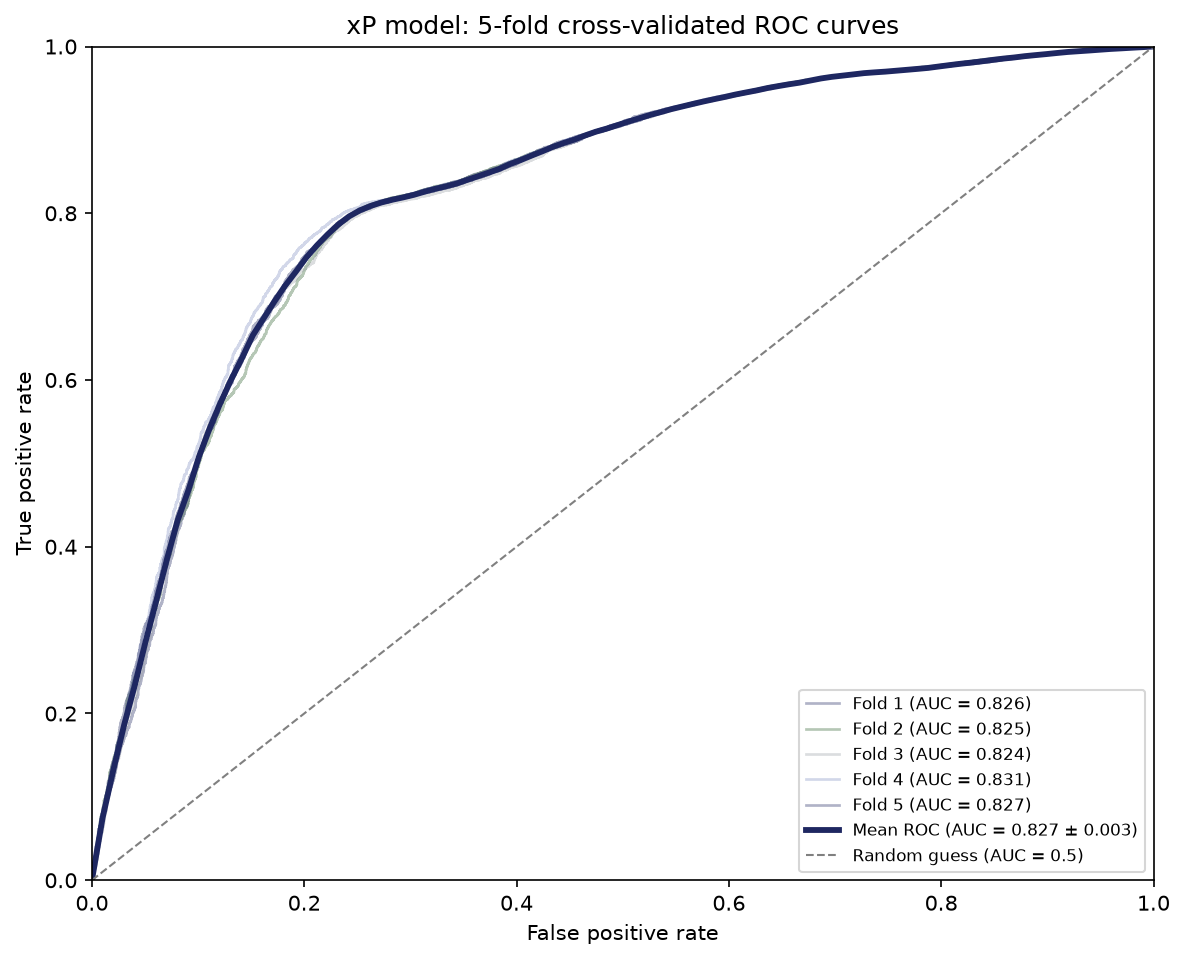

In [17]:
from sklearn.metrics import roc_curve
from sklearn.model_selection import StratifiedKFold

fig, ax = plt.subplots(figsize=(8, 6.5), dpi=150)

skf = StratifiedKFold(n_splits=5, shuffle=True, random_state=42)
mean_fpr = np.linspace(0, 1, 100)
tprs = []

for fold_i, (train_idx, test_idx) in enumerate(skf.split(X_xp_all, y_xp_all)):
    X_train_fold, X_test_fold = X_xp_all.iloc[train_idx], X_xp_all.iloc[test_idx]
    y_train_fold, y_test_fold = y_xp_all.iloc[train_idx], y_xp_all.iloc[test_idx]

    fold_model = LogisticRegression()
    fold_model.fit(X_train_fold, y_train_fold)
    probs = fold_model.predict_proba(X_test_fold)[:, 1]

    fpr, tpr, _ = roc_curve(y_test_fold, probs)
    fold_auc = roc_auc_score(y_test_fold, probs)
    ax.plot(fpr, tpr, alpha=0.35, linewidth=1.3, label=f"Fold {fold_i+1} (AUC = {fold_auc:.3f})")

    interp_tpr = np.interp(mean_fpr, fpr, tpr)
    interp_tpr[0] = 0.0
    tprs.append(interp_tpr)

mean_tpr = np.mean(tprs, axis=0)
mean_tpr[-1] = 1.0
mean_auc = roc_auc_score(y_xp_all, xp_model_full.predict_proba(X_xp_all)[:, 1])  # full-model reference

ax.plot(mean_fpr, mean_tpr, color='#1E2761', linewidth=2.8,
        label=f"Mean ROC (AUC = {cv_aucs.mean():.3f} $\\pm$ {cv_aucs.std():.3f})")

ax.plot([0, 1], [0, 1], linestyle='--', color='grey', linewidth=1, label="Random guess (AUC = 0.5)")

ax.set_xlabel("False positive rate")
ax.set_ylabel("True positive rate")
ax.set_title("xP model: 5-fold cross-validated ROC curves")
ax.legend(loc="lower right", fontsize=8)
ax.set_xlim(0, 1)
ax.set_ylim(0, 1)
fig.tight_layout()

save_fig(fig, 'rq2_xp_model_roc_curves.png')

plt.show()

**What this shows:** the 5 fold curves lie almost on top of each other, matching the small standard deviation above, and stay well clear of the random diagonal. The flattening around a false positive rate of 0.2 to 0.25 is where the easy passes run out and the more ambiguous ones start, as expected for a three-feature model.

## 3. Offside and xP for every candidate

### The candidate table from Layer 1

`candidates_all3` has one row per teammate who was a possible receiver of each pass: their location, whether they were inside the vision cone, the VAEP value of a pass to them, and the value of the pass actually made. These are the corrected values from the coordinate fix at the end of `01_layer1_visual_constraint.ipynb`, so the real pass value is available for every pass, including passes where no teammate was visible.

In [18]:
candidate_files = glob.glob('../data/candidates_all3_fixed/candidates_match_*.pkl')
candidates_all3 = pd.concat([pd.read_pickle(f) for f in candidate_files], ignore_index=True)
print(f"{len(candidate_files)} matches, {len(candidates_all3)} candidate rows")
print(f"{candidates_all3['real_value'].isna().sum()} rows missing a real_value (should be 0)")

166 matches, 664510 candidate rows
0 rows missing a real_value (should be 0)


**What this shows:** every candidate row now has a real pass value.

Before the coordinate fix, the real value came from the RQ1 table, which only keeps passes with at least one visible teammate. That left 101193 rows without a real value, all of them invisible teammates on passes where nobody was visible, and those rows could never count as maximal-VAEP options. This did not affect the headline RQ2 rate, which only counts visible candidates, but it held down the invisible groups in the three-way split in `07_layer3_memory_feasibility.ipynb`. The corrected candidate files store the real value for every pass, computed in exactly the same way.

### Offside status and xP in one pass over the frames

`candidates_all3` has the candidate and passer locations, but not the defender positions needed for offside and xP, which are in the 360 frame. The frames are loaded once per match (from the cache where available). For every pass, the offside line is computed once and the xP features for every candidate of that pass, using the same frame for both.

In [19]:
from collections import defaultdict

unique_match_ids = candidates_all3['match_id'].unique()
combined_rows = []
skipped_events = 0

# group once per match, and once per event within each match, instead of
# filtering the full 664k-row table from scratch for every single event
candidates_by_match = {mid: df for mid, df in candidates_all3.groupby('match_id')}

for i, mid in enumerate(unique_match_ids):
    m_frames = cached_frames(str(mid))
    m_events = cached_events(str(mid))
    m_events_indexed = m_events.set_index('id')

    match_candidates = candidates_by_match[mid]
    candidates_by_event = {eid: df for eid, df in match_candidates.groupby('original_event_id')}
    match_event_ids = match_candidates['original_event_id'].unique()

    # first pass: collect the opponent keeper's x-position wherever it happens to be
    # visible, grouped by team and period, so a missing keeper in one frame can fall
    # back to a robust estimate from other passes by the same team in the same half
    keeper_positions = defaultdict(list)
    event_frames = {}
    event_team_period = {}

    for event_id in match_event_ids:
        frame_at_event = m_frames[m_frames['id'] == event_id]
        event_frames[event_id] = frame_at_event
        if frame_at_event.empty:
            continue
        if event_id not in m_events_indexed.index:
            continue
        ev = m_events_indexed.loc[event_id]
        team = ev['team']
        period = ev['period']
        event_team_period[event_id] = (team, period)

        opponent_keeper = frame_at_event[(frame_at_event['teammate'] == False) & (frame_at_event['keeper'] == True)]
        if not opponent_keeper.empty:
            keeper_positions[(team, period)].append(opponent_keeper.iloc[0]['location'][0])

    attacking_direction = {key: np.median(vals) for key, vals in keeper_positions.items()}

    # second pass: classify every event, preferring its own keeper position when
    # visible, falling back to the team and period estimate otherwise. xp_value
    # is not computed here anymore, just the features, so the model only runs once
    # at the very end on the full batch
    for event_id in match_event_ids:
        frame_at_event = event_frames[event_id]
        if frame_at_event.empty:
            skipped_events += 1
            continue

        team_period = event_team_period.get(event_id)
        opponent_keeper = frame_at_event[(frame_at_event['teammate'] == False) & (frame_at_event['keeper'] == True)]
        if not opponent_keeper.empty:
            attacking_toward_x = opponent_keeper.iloc[0]['location'][0]
        elif team_period in attacking_direction:
            attacking_toward_x = attacking_direction[team_period]
        else:
            skipped_events += 1
            continue

        offside_line_x = compute_offside_line(frame_at_event, attacking_toward_x)

        event_candidates = candidates_by_event.get(event_id)
        if event_candidates is None or event_candidates.empty:
            continue
        passer_loc = event_candidates.iloc[0]['passer_location']

        for _, row in event_candidates.iterrows():
            cand_loc = row['candidate_location']
            offside = is_offside(cand_loc[0], passer_loc[0], offside_line_x, attacking_toward_x)
            xp_features = compute_xp_features(passer_loc, cand_loc, frame_at_event)

            combined_rows.append({
                'match_id': mid,
                'original_event_id': event_id,
                'cand_x': round(cand_loc[0], 4),
                'cand_y': round(cand_loc[1], 4),
                'offside': offside,
                'xp_features': xp_features,
                'attacking_toward_x': attacking_toward_x,
            })

    if (i + 1) % 20 == 0:
        print(f"[{i+1}/{len(unique_match_ids)}] matches processed, {skipped_events} events skipped so far")

print(f"Done classifying offside and features. {len(combined_rows)} candidate rows. {skipped_events} events skipped entirely (no frame data and no team/period fallback available).")

# batch the xP prediction in a single call instead of one row at a time
filters_df = pd.DataFrame(combined_rows)
xp_feature_df = pd.DataFrame(list(filters_df['xp_features']))
filters_df['xp_value'] = xp_model_full.predict_proba(xp_feature_df)[:, 1]
filters_df = filters_df.drop(columns=['xp_features'])

candidates_all3['cand_x'] = candidates_all3['candidate_location'].apply(lambda loc: round(loc[0], 4))
candidates_all3['cand_y'] = candidates_all3['candidate_location'].apply(lambda loc: round(loc[1], 4))

candidates_full = candidates_all3.merge(
    filters_df,
    on=['match_id', 'original_event_id', 'cand_x', 'cand_y'],
    how='left'
)
print(f"{len(candidates_full)} rows after merge, {candidates_full['offside'].isna().sum()} unmatched")
print(candidates_full['offside'].value_counts())

[20/166] matches processed, 206 events skipped so far
[40/166] matches processed, 291 events skipped so far
[60/166] matches processed, 369 events skipped so far
[80/166] matches processed, 446 events skipped so far
[100/166] matches processed, 524 events skipped so far
[120/166] matches processed, 530 events skipped so far
[140/166] matches processed, 530 events skipped so far
[160/166] matches processed, 582 events skipped so far
Done classifying offside and features. 660784 candidate rows. 582 events skipped entirely (no frame data and no team/period fallback available).
664518 rows after merge, 3726 unmatched
offside
False    637620
True      23172
Name: count, dtype: int64


**What this shows**

**Almost every candidate was classified.** Of 664518 candidate rows, 660792 got an offside status and an xP value; 3726 (0.56 percent) could not be matched. The merge adds 8 rows to the 664510 candidates, where two teammates in the same frame share the same rounded position. Those rows are identical copies, so they cannot change any pass-level result and change candidate-level shares by less than 0.001 percent.

**Two corrections to the offside logic.**

- **The missing goalkeeper.** The goalkeeper is on camera in only 14.0 percent of event frames, a known blind spot of StatsBomb 360, so most offside lines need a fallback. The first fallback used the second-deepest visible outfield defender, which is too shallow, since the keeper is almost always deeper than every outfield player. The corrected version uses the deepest visible outfield defender, which approximates where the true line would be.
- **The own-half exemption.** A player can never be offside in their own half, which the first version did not check. Before this fix, 32.48 percent of the candidates flagged offside under the keeper correction (11148 of 34320) were in their own half.

**Together, the two corrections change the offside rate substantially.** 23172 candidates (3.5 percent) are now offside, against 34320 (5.2 percent) with the keeper fix alone and 73714 (11.1 percent) with neither. The corrected figures are used throughout the rest of this notebook.

### Does the choice of xP model matter?

The xP model is a deliberately simple logistic regression on three features, used only as a floor (`XP_THRESHOLD = 0.05`) to exclude unrealistically difficult passes from the pool of legitimate maximal-VAEP options. Since the model could in principle change which candidates clear that floor, a gradient boosting model (scikit-learn's `HistGradientBoostingClassifier`) is trained on the same three features. The two models are compared on held-out AUC and on how many candidates change side of the 0.05 floor.

In [20]:
from sklearn.ensemble import HistGradientBoostingClassifier

gb_model_full = HistGradientBoostingClassifier(random_state=42)
gb_model_full.fit(X_train, y_train)

gb_auc_full = roc_auc_score(y_test, gb_model_full.predict_proba(X_test)[:, 1])
print(f"Gradient boosting xP model AUC (full dataset): {gb_auc_full:.3f}")
print(f"Logistic regression xP model AUC (for comparison): {auc_full:.3f}")

Gradient boosting xP model AUC (full dataset): 0.858
Logistic regression xP model AUC (for comparison): 0.823


In [21]:
# apply the gradient boosting model to the same candidate feature set used
# for the logistic regression classification (reuse xp_feature_df from your
# existing classification cell)
gb_xp_values = gb_model_full.predict_proba(xp_feature_df)[:, 1]

comparison_df = filters_df.copy()
comparison_df['xp_value_lr'] = comparison_df['xp_value']  # existing logistic regression xp
comparison_df['xp_value_gb'] = gb_xp_values

# how many candidates flip across the 0.05 threshold between models?
flipped = (comparison_df['xp_value_lr'] >= 0.05) != (comparison_df['xp_value_gb'] >= 0.05)
print(f"Candidates that flip across the 0.05 threshold: {flipped.sum()} of {len(comparison_df)} ({flipped.mean():.2%})")

Candidates that flip across the 0.05 threshold: 4406 of 660784 (0.67%)


**What this shows**

**Gradient boosting fits slightly better.** Its held-out AUC is 0.858, against 0.823 for the logistic regression. This fits the nonlinear interactions between the features (for example, distance and defender proximity compounding each other) that an additive model cannot capture.

**But it changes almost no decisions.** Only 4406 of 660784 candidates (0.67 percent) change side of the 0.05 floor between the two models. Because xP is used only as a yes/no floor in RQ2, this is the number that decides whether the model choice matters, not the AUC.

So the bypass rate does not depend on this choice. The logistic regression is kept for its interpretability and its grounding in the pass-difficulty literature.

## 4. xT and maximal-VAEP options

### Checking the xT grid

In [22]:
import numpy as np
from scipy.interpolate import RegularGridInterpolator
from socceraction.spadl import config as spadlconfig

# socceraction's own interpolator() method calls scipy's interp2d, which was
# removed in scipy 1.14+. this rebuilds the same interpolation using
# RegularGridInterpolator instead, working directly off the loaded xT grid

_xt_grid = xT_model.xT  # shape (n_y_bins, n_x_bins)
_n_y_bins, _n_x_bins = _xt_grid.shape
_cell_length = spadlconfig.field_length / _n_x_bins
_cell_width = spadlconfig.field_width / _n_y_bins
_x_centers = np.arange(0.0, spadlconfig.field_length, _cell_length) + 0.5 * _cell_length
_y_centers = np.arange(0.0, spadlconfig.field_width, _cell_width) + 0.5 * _cell_width

_xt_interpolator = RegularGridInterpolator(
    (_x_centers, _y_centers),
    _xt_grid.T,
    bounds_error=False,
    fill_value=None,
)

def get_xt_value(x, y):
    x_clipped = np.clip(x, 0, spadlconfig.field_length)
    y_clipped = np.clip(y, 0, spadlconfig.field_width)
    return float(_xt_interpolator([[x_clipped, y_clipped]])[0])

# same sanity check as before, now using get_xt_value instead of xT_model.interpolator()
test_points = [
    (60, 40, "halfway line, center"),
    (100, 40, "edge of box, center"),
    (114, 40, "six-yard box, center"),
    (20, 40, "own defensive third, center"),
    (100, 5, "edge of box, wide touchline"),
]

for x, y, label in test_points:
    val = get_xt_value(x, y)
    print(f"{label}: ({x}, {y}) -> xT = {val:.4f}")

halfway line, center: (60, 40) -> xT = 0.0179
edge of box, center: (100, 40) -> xT = 0.2091
six-yard box, center: (114, 40) -> xT = 0.2780
own defensive third, center: (20, 40) -> xT = 0.0102
edge of box, wide touchline: (100, 5) -> xT = 0.0384


**The xT unit fix.** The xT grid is on SPADL's 105 x 68 metre pitch, but passer and candidate locations are on StatsBomb's 120 x 80 pitch. The first version of `get_xt_value` passed StatsBomb numbers straight into the metre grid. For example, x = 100 (about 20 yards from goal) was read as 100 metres (5 metres from goal), and anything beyond x = 105 or y = 68 was clipped to the edge of the grid.

The cell below converts locations to SPADL metres first, the same conversion as the coordinate fix in Layer 1. The original function is kept as `get_xt_value_old` only so the next cell can show what changed. The values printed by the check above use the old, unconverted inputs.

In [23]:
# xT unit fix. The xT grid sits on SPADL's 105 x 68 metre pitch, but the event and freeze-frame
# locations are on StatsBomb's 120 x 80 yard pitch. The first version passed StatsBomb
# coordinates straight into the metre grid, so x = 100 (about 20 yards from goal) was read as
# 100 metres (5 metres from goal), and everything beyond x = 105 or y = 68 was clipped to the edge.
# Locations are now converted the same way as in the VAEP coordinate fix (layer 1). No mirroring
# is needed: StatsBomb already has the acting team attacking toward x = 120, and the xT grid has
# the attacking team playing toward x = 105.

def sb_to_spadl_attacking(x, y):
    """StatsBomb location (acting team attacking toward x=120) to SPADL metres, attacking toward x=105."""
    x = np.clip((np.asarray(x, dtype=float) - 0.5) / 120 * 105, 0, 105)
    y = np.clip(68 - (np.asarray(y, dtype=float) - 0.5) / 80 * 68, 0, 68)
    return x, y


def get_xt_value(x, y, attacking_toward_x=None):
    """xT at StatsBomb locations, for single values or arrays. attacking_toward_x is still accepted
    so older calls keep working, but it is not needed and not used."""
    xm, ym = sb_to_spadl_attacking(x, y)
    out = _xt_interpolator(np.column_stack([np.atleast_1d(xm), np.atleast_1d(ym)]))
    return float(out[0]) if np.ndim(x) == 0 else out


def get_xt_value_old(x, y, attacking_toward_x):
    """The original version (yards read as metres, plus the attacking-direction flip), kept only
    to measure what the fix changes."""
    x = np.asarray(x, dtype=float)
    y = np.asarray(y, dtype=float)
    x = np.where(np.asarray(attacking_toward_x, dtype=float) < 60, 120 - x, x)
    pts = np.column_stack([np.clip(x, 0, spadlconfig.field_length), np.clip(y, 0, spadlconfig.field_width)])
    return _xt_interpolator(pts)


# the sanity check again, in StatsBomb coordinates, old against fixed
test_points = [
    (60, 40, "halfway line, centre"),
    (102, 40, "edge of the box, centre"),
    (114, 40, "six-yard box, centre"),
    (20, 40, "own defensive third, centre"),
    (102, 5, "level with the edge of the box, near touchline"),
    (102, 75, "level with the edge of the box, far touchline"),
]
print(f"{'location':56s} {'old':>7s} {'fixed':>7s}")
for x, y, label in test_points:
    old = get_xt_value_old([x], [y], [120])[0]
    print(f"{label + f' ({x}, {y})':56s} {old:7.4f} {get_xt_value(x, y):7.4f}")

location                                                     old   fixed
halfway line, centre (60, 40)                             0.0179  0.0158
edge of the box, centre (102, 40)                         0.2367  0.0825
six-yard box, centre (114, 40)                            0.2780  0.2350
own defensive third, centre (20, 40)                      0.0102  0.0105
level with the edge of the box, near touchline (102, 5)   0.0392  0.0321
level with the edge of the box, far touchline (102, 75)   0.0339  0.0325


### Maximal-VAEP options and the legitimate pool

- **Maximal-VAEP option:** a candidate whose target zone has higher xT than the passer's zone, and whose VAEP value is higher than the value of the pass actually made.
- **Legitimate:** the candidate is also visible, onside, and has at least a minimal completion probability (xP of 0.05 or more).

In [24]:
px = candidates_full['passer_location'].str[0].to_numpy()
py = candidates_full['passer_location'].str[1].to_numpy()
cx = candidates_full['candidate_location'].str[0].to_numpy()
cy = candidates_full['candidate_location'].str[1].to_numpy()
atx = candidates_full['attacking_toward_x'].to_numpy()

# old values, kept only for the comparison printed below
candidates_full['xt_origin_old'] = get_xt_value_old(px, py, atx)
candidates_full['xt_target_old'] = get_xt_value_old(cx, cy, atx)

# fixed values, used from here on
candidates_full['xt_origin'] = get_xt_value(px, py)
candidates_full['xt_target'] = get_xt_value(cx, cy)

candidates_full['maximal_vaep'] = (
    (candidates_full['xt_target'] > candidates_full['xt_origin']) &
    (candidates_full['candidate_value'] > candidates_full['real_value'])
)

XP_THRESHOLD = 0.05  # unrealistically difficult passes excluded below this, tune if needed

candidates_full['legitimate_maximal_vaep'] = (
    candidates_full['visible']
    & candidates_full['offside'].eq(False)    # onside; rows with no offside result count as not onside, as before
    & (candidates_full['xp_value'] >= XP_THRESHOLD)
    & candidates_full['maximal_vaep']
)

print(candidates_full['maximal_vaep'].value_counts())
print(candidates_full['legitimate_maximal_vaep'].value_counts())

# what the unit fix changed
fp_old = ((candidates_full['xt_target_old'] > candidates_full['xt_origin_old'])
          & (candidates_full['candidate_value'] > candidates_full['real_value']))
legit_old = (candidates_full['visible'] & candidates_full['offside'].eq(False)
             & (candidates_full['xp_value'] >= XP_THRESHOLD) & fp_old)
print(f"\nrows where the old version flipped the pitch (attacking_toward_x < 60): {(atx < 60).sum()}")
print(f"candidates whose 'moves to higher xT' result changed: "
      f"{((candidates_full['xt_target_old'] > candidates_full['xt_origin_old']) != (candidates_full['xt_target'] > candidates_full['xt_origin'])).mean():.2%}")
print(f"maximal-VAEP candidates: {fp_old.sum()} before, {candidates_full['maximal_vaep'].sum()} after")
print(f"legitimate candidates: {legit_old.sum()} before, {candidates_full['legitimate_maximal_vaep'].sum()} after")
keys = ['match_id', 'original_event_id']
rate_old = legit_old.groupby([candidates_full[k] for k in keys]).any().mean()
rate_new = candidates_full.groupby(keys)['legitimate_maximal_vaep'].any().mean()
print(f"bypass rate: {rate_old:.1%} before, {rate_new:.1%} after")

maximal_vaep
False    408526
True     255992
Name: count, dtype: int64
legitimate_maximal_vaep
False    588248
True      76270
Name: count, dtype: int64

rows where the old version flipped the pitch (attacking_toward_x < 60): 147
candidates whose 'moves to higher xT' result changed: 8.40%
maximal-VAEP candidates: 251253 before, 255992 after
legitimate candidates: 75174 before, 76270 after
bypass rate: 38.5% before, 38.9% after


**What this shows**

**The xT fix matters near the opponent's goal and hardly anywhere else.** In the check above:

| Location | Old xT | Corrected xT |
|---|---|---|
| Centre of the edge of the box | 0.237 | 0.083 |
| Six-yard box | 0.278 | 0.235 |
| Halfway line | 0.018 | 0.016 |
| Defensive third | 0.010 | 0.011 |

The edge of the box drops most because the old version read x = 102 as 102 metres, about 3 metres from the goal line. The old version also flipped the pitch for 147 candidate rows whose estimated attacking direction was below x = 60. That flip was never needed, since StatsBomb already records every event with the acting team attacking toward x = 120.

**The headline result barely moves.** For 8.40 percent of candidates, the answer to "is the teammate in a higher-threat spot than the passer?" changed. Changes in both directions mostly cancel out:

- maximal-VAEP candidates rise from 251253 to 255992;
- legitimate candidates rise from 75174 to 76270;
- the bypass rate moves from 38.5 to 38.9 percent.

Every figure from here on uses the corrected xT.

**What this shows**

**About one candidate in nine is a legitimate maximal-VAEP option.** Of 664518 candidate rows, 255992 (38.5 percent) are maximal-VAEP options: the target zone has higher expected threat than the passer's zone, and the candidate's VAEP value is higher than the pass actually made. Requiring the candidate also to be visible, onside and above the 0.05 completion floor leaves 76270 legitimate maximal-VAEP options, 11.5 percent of all candidates.

**The effect of the coordinate fix.** Before it, these figures were 252780 maximal-VAEP and 95464 legitimate. The legitimate pool, which only contains visible candidates, shrank by about a fifth, because the old values overstated how valuable a pass to a forward teammate would be. The maximal-VAEP total barely moved, because two changes offset each other: corrected values removed many inflated maximal-VAEP options, while invisible teammates on passes with no visible teammate could now qualify, since they have a real value to compare against.

**The effect of the xT unit fix.** It then added a small number to both counts (from 251253 and 75174).

## 5. The RQ2 bypass rate

As in the proposal (Section 4.5.2): for every pass, was at least one legitimate maximal-VAEP alternative available and bypassed? A candidate only counts as a maximal-VAEP option when its value exceeds the real pass's value. So a pass where the player took the best option has no qualifying candidate by construction, and the chosen teammate does not need to be excluded separately.

In [25]:
from scipy.stats import binomtest

pass_level = candidates_full.groupby(['match_id', 'original_event_id']).agg(
    had_legit_option=('legitimate_maximal_vaep', 'any')
).reset_index()

n_total = len(pass_level)
n_bypassed = pass_level['had_legit_option'].sum()
bypass_rate = n_bypassed / n_total

print(f"Total passes: {n_total}")
print(f"Passes with a legitimate maximal-VAEP option that was bypassed: {n_bypassed}")
print(f"Bypass rate: {bypass_rate:.1%}")

result = binomtest(n_bypassed, n_total, p=0.5)
print(f"Binomial test vs random selection: p={result.pvalue:.4f}")

pass_level.to_pickle('../data/results/rq2_bypass_rate.pkl')

Total passes: 98652
Passes with a legitimate maximal-VAEP option that was bypassed: 38418
Bypass rate: 38.9%
Binomial test vs random selection: p=0.0000


**What this shows**

**About two passes in five bypass a legitimate maximal-VAEP option.** Across 98652 qualifying passes, 38418 (38.9 percent) had at least one visible, onside and completable maximal-VAEP alternative that the player did not take.

| Version | Passes | Rate |
|---|---|---|
| Before the coordinate fix | 44932 | 45.5% |
| After the coordinate fix, before the xT unit fix | 37966 | 38.5% |
| Corrected | 38418 | 38.9% |

So the corrected rate is 6.6 percentage points below the original, almost all of it from the coordinate fix.

**The effect size carries the argument, not the p-value.** A binomial test against 50 percent is significant (p < 0.0001), but with a sample this large even a modest deviation from 50 percent is significant. The 50 percent is a reference point, not a chance model of passing. What matters is that roughly two in five qualifying passes bypassed an option that perception, offside status and pass difficulty all suggest was available and reasonable.

In [26]:
import numpy as np
from scipy.stats import norm

def wilson_ci(n_success, n_total, alpha=0.05):
    z = norm.ppf(1 - alpha / 2)
    phat = n_success / n_total
    denom = 1 + z**2 / n_total
    centre = phat + z**2 / (2 * n_total)
    adj = z * np.sqrt(phat * (1 - phat) / n_total + z**2 / (4 * n_total**2))
    return (centre - adj) / denom, (centre + adj) / denom

ci_low, ci_high = wilson_ci(n_bypassed, n_total)
print(f"Bypass rate: {bypass_rate:.1%} (95% CI: {ci_low:.1%} to {ci_high:.1%})")

Bypass rate: 38.9% (95% CI: 38.6% to 39.2%)


### What the bypass rate means

RQ2 asks whether players pass backward or sideways even when a better maximal-VAEP option is genuinely available. Genuinely available means not just open somewhere on the pitch, but visible within their field of view, onside and realistically completable. The 38.9 percent rate means that in roughly two in five of the 98652 qualifying passes, a player had exactly this kind of option in front of them and chose not to take it.

**This is the central evidence for H2,** that decision-making bias exists independently of perceptual constraint. Layer 1 showed that many counterfactual options are invisible to the passer in the first place. This result goes further: even restricted to options the player could plausibly see and legally play, bypassing still happens in roughly two in five passes. Visibility has already been filtered for, so that gap is not explained by what the player could perceive. It points toward a genuine tendency toward caution or retention over forward progression, consistent with the directional bias literature.

**The finding is not that players make mistakes.** A bypassed maximal-VAEP option can still be the sensible choice for reasons the value model does not capture, such as game state, risk tolerance or a better second option nearby. Risk and game state are tested in `03_layer2_risk_and_context.ipynb`. The claim is narrower and better supported: forward progression is left on the table at a rate too high to put down to perception or legality alone.

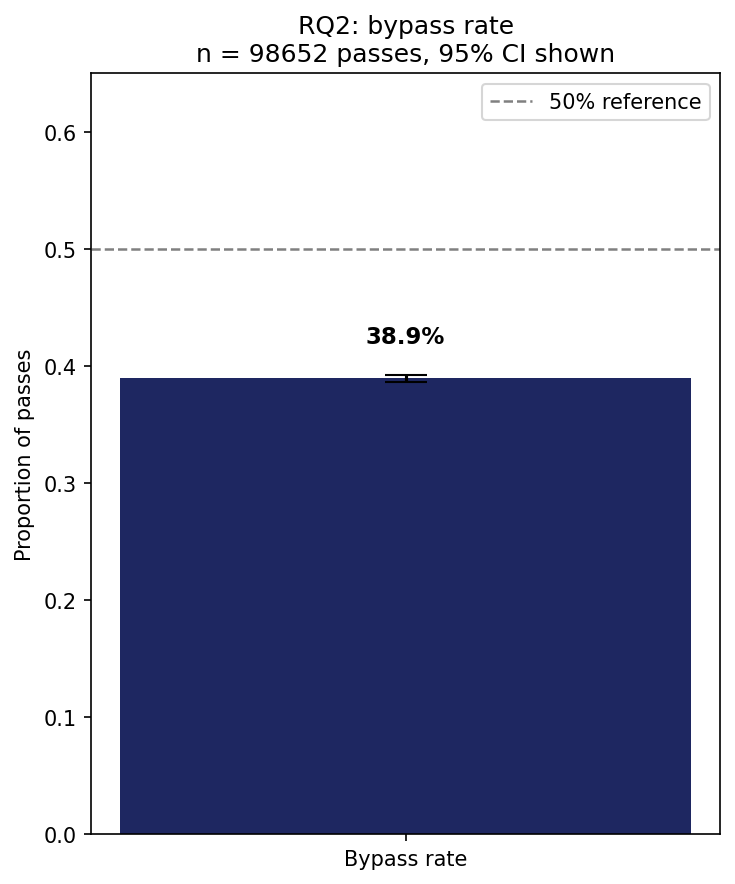

In [27]:
fig, ax = plt.subplots(figsize=(5, 6), dpi=150)

ax.bar(['Bypass rate'], [bypass_rate], color='#1E2761', width=0.45,
       yerr=[[bypass_rate - ci_low], [ci_high - bypass_rate]],
       capsize=10, ecolor='black', error_kw={'elinewidth': 1.5})
ax.axhline(0.5, linestyle='--', color='grey', linewidth=1.2, label='50% reference')

ax.set_ylim(0, 0.65)
ax.set_ylabel('Proportion of passes')
ax.set_title(f'RQ2: bypass rate\nn = {n_total} passes, 95% CI shown')
ax.legend(loc='upper right')
for i, v in enumerate([bypass_rate]):
    ax.text(i, v + 0.03, f"{v:.1%}", ha='center', fontsize=11, fontweight='bold')

fig.tight_layout()
# not saved: the Figures section saves the final version of this chart
plt.show()

**What this shows:** the bypass rate is 38.9 percent, with a narrow 95 percent interval of 38.6 to 39.2 percent, below the 50 percent reference line. The narrow interval reflects the large sample (98652 passes), not a small effect.

This Wilson interval treats every pass as independent. The interval from resampling whole matches, in section 6, is wider (38.1 to 39.8 percent) and is the one to report.

In [28]:
from scipy.stats import chi2_contingency

match_competition = {}
for mid in matches_euro2024['match_id']:
    match_competition[str(mid)] = 'Euro 2024'
for mid in matches_euro2020['match_id']:
    match_competition[str(mid)] = 'Euro 2020'
for mid in matches_wc2022['match_id']:
    match_competition[str(mid)] = 'World Cup 2022'

pass_level['competition'] = pass_level['match_id'].astype(str).map(match_competition)
print(pass_level['competition'].value_counts(dropna=False))

comp_summary = pass_level.groupby('competition')['had_legit_option'].agg(
    n_bypassed='sum', n_total='count'
)
comp_summary['rate'] = comp_summary['n_bypassed'] / comp_summary['n_total']

ci_low_arr, ci_high_arr = wilson_ci(comp_summary['n_bypassed'].values, comp_summary['n_total'].values)
comp_summary['ci_low'] = ci_low_arr
comp_summary['ci_high'] = ci_high_arr

print(comp_summary)

contingency = pd.crosstab(pass_level['competition'], pass_level['had_legit_option'])
chi2, p_chi2, dof, expected = chi2_contingency(contingency)
print(f"\nChi-square test for homogeneity across competitions: chi2={chi2:.3f}, p={p_chi2:.4f}")

competition
World Cup 2022    36753
Euro 2024         31537
Euro 2020         30362
Name: count, dtype: int64
                n_bypassed  n_total      rate    ci_low   ci_high
competition                                                      
Euro 2020            12030    30362  0.396219  0.390731  0.401733
Euro 2024            12801    31537  0.405904  0.400496  0.411335
World Cup 2022       13587    36753  0.369684  0.364763  0.374633

Chi-square test for homogeneity across competitions: chi2=102.149, p=0.0000


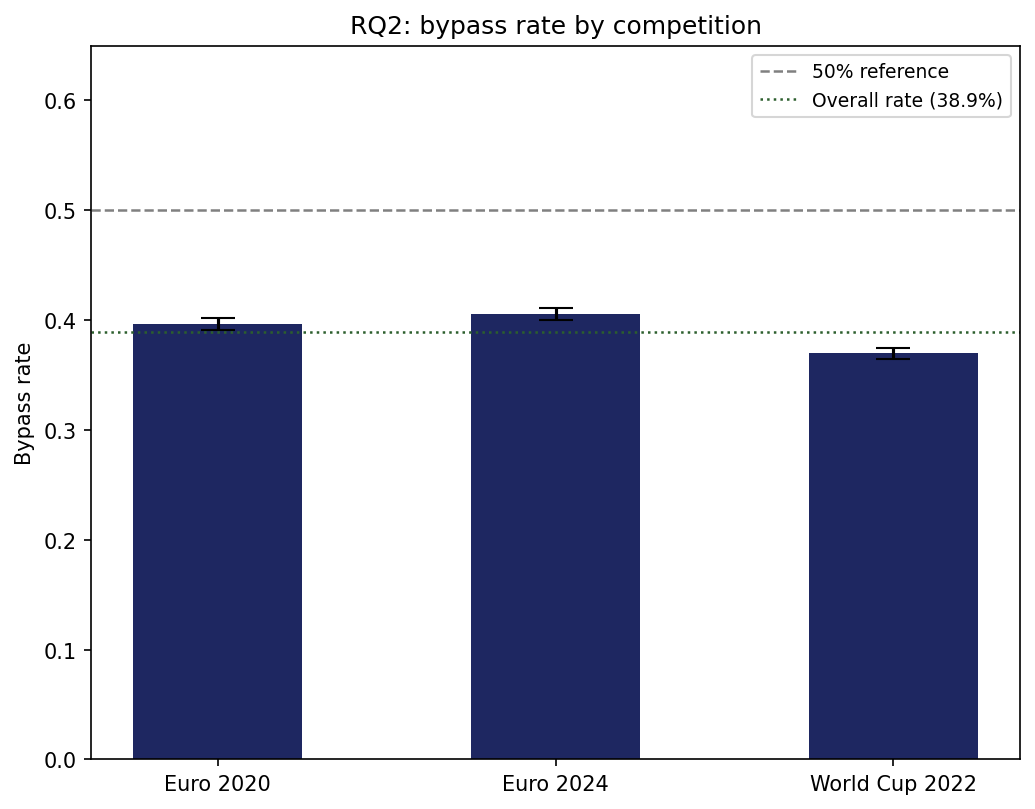

In [29]:
fig, ax = plt.subplots(figsize=(7, 5.5), dpi=150)

comps = comp_summary.index.tolist()
rates = comp_summary['rate'].values
err_low = rates - comp_summary['ci_low'].values
err_high = comp_summary['ci_high'].values - rates

ax.bar(comps, rates, color='#1E2761', width=0.5,
       yerr=[err_low, err_high], capsize=8, ecolor='black')
ax.axhline(0.5, linestyle='--', color='grey', linewidth=1.2, label='50% reference')
ax.axhline(bypass_rate, linestyle=':', color='#2C5F2D', linewidth=1.2, label=f'Overall rate ({bypass_rate:.1%})')

ax.set_ylim(0, 0.65)
ax.set_ylabel('Bypass rate')
ax.set_title('RQ2: bypass rate by competition')
ax.legend(loc='upper right', fontsize=9)

fig.tight_layout()
# not saved: the Figures section saves the final version of this chart
plt.show()

### The bypass rate by competition

**What this shows:** the rate holds in all three tournaments:

| Competition | Bypass rate |
|---|---|
| World Cup 2022 | 37.0% |
| Euro 2020 | 39.6% |
| Euro 2024 | 40.6% |

The chi-square test finds the difference significant (chi2 = 102.149, p < 0.0001). But with a sample this large, as with the binomial test, significance does not imply a practically large difference. A spread of 3.6 percentage points is modest across three tournaments played years apart, under different formats and with different squads. All three show players bypassing a legitimate maximal-VAEP option in roughly two in five passes. The order of the tournaments is the same as before the coordinate and xT fixes, so the finding is not an artifact of any single tournament.

### Are the maximal-VAEP options really forward?

A maximal-VAEP option needs a target zone with higher xT than the passer's zone. The xT grid rises toward the centre of the pitch as well as toward goal, and in a team's own half its values are almost flat. So an option can qualify while lying level with or even behind the passer, for example a pass back into the centre from a wide position.

This cell measures how often that happens, and recomputes the bypass rate counting only options that are at least 0, 5 or 10 yards ahead of the passer. Nothing else changes.

In [30]:
ahead = candidates_full['cand_x'] - candidates_full['passer_location'].str[0]   # yards toward the opponent goal
legit = candidates_full['legitimate_maximal_vaep'].fillna(False).astype(bool)
print(f"legitimate maximal-VAEP options behind the passer: {(ahead[legit] < 0).mean():.1%}; "
      f"less than 5 yd ahead: {(ahead[legit] < 5).mean():.1%}")
rows = []
for label, mask in [('any legitimate option (as reported)', legit), ('option ahead of the passer', legit & (ahead > 0)),
                    ('option at least 5 yd ahead', legit & (ahead > 5)), ('option at least 10 yd ahead', legit & (ahead > 10))]:
    k = candidates_full.loc[mask, 'original_event_id'].nunique()
    rows.append({'requirement': label, 'passes': k, 'bypass rate (%)': round(100 * k / n_total, 1)})
print(pd.DataFrame(rows).to_string(index=False))

legitimate maximal-VAEP options behind the passer: 9.7%; less than 5 yd ahead: 21.4%
                        requirement  passes  bypass rate (%)
any legitimate option (as reported)   38418                   38.9
         option ahead of the passer   35738                   36.2
         option at least 5 yd ahead   32378                   32.8
        option at least 10 yd ahead   26478                   26.8


**What this shows**

**About one legitimate option in ten is not ahead of the passer.** 9.7 percent of legitimate maximal-VAEP options lie behind the passer, and 7.0 percent of the 38418 flagged passes are flagged only because of such an option. This is why "maximal-VAEP" is the more accurate name than "forward-progressive": the definition rewards a better zone, which is usually but not always further forward.

**The finding survives a strict forward requirement.**

| Requirement on the bypassed option | Bypass rate |
|---|---|
| Any legitimate option (as reported) | 38.9% |
| Ahead of the passer | 36.2% |
| At least 5 yd ahead | 32.8% |
| At least 10 yd ahead | 26.8% |

Even when the bypassed option must be at least 10 yards further forward than the passer, about one pass in four leaves such an option unused. The reported 38.9 percent is kept as the headline because it follows the proposal's definition, but the strictly forward version (36.2 percent) is the safer number to quote when the claim is about forward passes specifically.

## 6. The bypass rate for visible, invisible and all teammates

The rate above only counts options inside the passer's vision cone. Here the same rate is computed for three pools of options:

- **visible teammates only:** the perception-aware rate above;
- **invisible teammates only;**
- **all teammates, regardless of visibility:** what a standard omniscient model would report.

The gap between the omniscient and visible rates shows how much of the bias an omniscient model would attribute to passers comes from options they could not see. This is the RQ2 counterpart of RQ1.

All three pools use the same filters: onside, xP of at least 0.05, and maximal-VAEP by xT and VAEP. Rates are given over all 98652 qualifying passes, as in the headline figure, and over only the passes where that pool contains at least one teammate, since about one pass in six has no visible teammate. Intervals come from resampling whole matches.

In [31]:
XP_THRESHOLD = 0.05
usable = (~candidates_full['offside'].fillna(True).astype(bool)) & (candidates_full['xp_value'] >= XP_THRESHOLD) \
         & candidates_full['maximal_vaep']
pools = candidates_full[['match_id', 'original_event_id', 'visible']].assign(
    legit_visible=usable & candidates_full['visible'],
    legit_invisible=usable & ~candidates_full['visible'],
    legit_all=usable,
)
assert (pools['legit_visible'] == candidates_full['legitimate_maximal_vaep']).all(), \
    "visible pool should reproduce the existing legitimate_maximal_vaep column"

pass_pools = pools.groupby(['match_id', 'original_event_id']).agg(
    visible=('legit_visible', 'any'),
    invisible=('legit_invisible', 'any'),
    all_teammates=('legit_all', 'any'),
    n_visible=('visible', 'sum'),
    n_teammates=('visible', 'size'),
).reset_index()
pass_pools['has_visible'] = pass_pools['n_visible'] > 0
pass_pools['has_invisible'] = pass_pools['n_teammates'] > pass_pools['n_visible']


def rate_ci(df, cols, n_boot=5000, seed=0):
    """Share of passes where each column is True, with 95% intervals from resampling whole matches."""
    per_match = df.groupby('match_id')[cols].agg(['sum', 'count'])
    S = np.column_stack([per_match[(c, 'sum')] for c in cols]).astype(float)
    C = np.column_stack([per_match[(c, 'count')] for c in cols]).astype(float)
    idx = np.random.default_rng(seed).integers(0, len(per_match), size=(n_boot, len(per_match)))
    boot = S[idx].sum(axis=1) / C[idx].sum(axis=1)
    point = S.sum(axis=0) / C.sum(axis=0)
    return pd.DataFrame({'passes': C.sum(axis=0).astype(int), 'rate': point,
                         'ci_low': np.percentile(boot, 2.5, axis=0),
                         'ci_high': np.percentile(boot, 97.5, axis=0)}, index=cols)


cols = ['visible', 'invisible', 'all_teammates']
print("1. Bypass rate by option pool, over all qualifying passes")
print(rate_ci(pass_pools, cols).round(4).to_string())

print("\n2. The same, only over passes where the pool contains at least one teammate")
print(pd.concat([
    rate_ci(pass_pools[pass_pools['has_visible']], ['visible']),
    rate_ci(pass_pools[pass_pools['has_invisible']], ['invisible']),
    rate_ci(pass_pools, ['all_teammates']),
]).round(4).to_string())

print("\n3. How the omniscient (all teammates) rate splits up")
only_vis = pass_pools['visible'] & ~pass_pools['invisible']
only_inv = pass_pools['invisible'] & ~pass_pools['visible']
both = pass_pools['visible'] & pass_pools['invisible']
n = len(pass_pools)
for label, m in [('legitimate option only among visible teammates', only_vis),
                 ('legitimate option only among invisible teammates', only_inv),
                 ('legitimate options in both', both)]:
    print(f"  {label}: {m.sum()} passes ({m.sum() / n:.1%})")
print(f"  omniscient rate {pass_pools['all_teammates'].mean():.1%} against perception-aware (visible) "
      f"rate {pass_pools['visible'].mean():.1%}: {only_inv.sum()} passes "
      f"({only_inv.sum() / pass_pools['all_teammates'].sum():.1%} of the omniscient count) are only "
      f"'bypassed' because of options the passer could not see")

print("\n4. Candidate level: share of teammates in each pool that are legitimate maximal-VAEP options")
print(pd.Series({
    'visible': pools.loc[pools['visible'], 'legit_visible'].mean(),
    'invisible': pools.loc[~pools['visible'], 'legit_invisible'].mean(),
    'all_teammates': pools['legit_all'].mean(),
}).round(4).to_string())

pass_pools.to_pickle('../data/results/rq2_rate_by_pool.pkl')

C:\Users\raees\AppData\Local\Temp\ipykernel_26308\4187953234.py:2: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  usable = (~candidates_full['offside'].fillna(True).astype(bool)) & (candidates_full['xp_value'] >= XP_THRESHOLD) \


1. Bypass rate by option pool, over all qualifying passes
               passes    rate  ci_low  ci_high
visible         98652  0.3894  0.3805   0.3984
invisible       98652  0.6126  0.6052   0.6200
all_teammates   98652  0.7425  0.7346   0.7502

2. The same, only over passes where the pool contains at least one teammate
               passes    rate  ci_low  ci_high
visible         82045  0.4683  0.4591   0.4773
invisible       97167  0.6220  0.6147   0.6293
all_teammates   98652  0.7425  0.7346   0.7502

3. How the omniscient (all teammates) rate splits up
  legitimate option only among visible teammates: 12813 passes (13.0%)
  legitimate option only among invisible teammates: 34831 passes (35.3%)
  legitimate options in both: 25605 passes (26.0%)
  omniscient rate 74.2% against perception-aware (visible) rate 38.9%: 34831 passes (47.6% of the omniscient count) are only 'bypassed' because of options the passer could not see

4. Candidate level: share of teammates in each pool that ar

**What this shows**

**Over all 98652 qualifying passes, a legitimate maximal-VAEP option was bypassed** (95 percent intervals from resampling whole matches):

| Pool | Rate | 95% CI |
|---|---|---|
| Visible teammates | 38.9% | 38.1 to 39.8 |
| Invisible teammates | 61.3% | 60.5 to 62.0 |
| All teammates | 74.2% | 73.5 to 75.0 |

Counting only passes where the pool contains at least one teammate, the visible rate is 46.8 percent (82045 passes) and the invisible rate 62.2 percent (97167 passes).

**The omniscient rate is almost double the perception-aware one.** Splitting up the 74.2 percent:

- in 13.0 percent of passes the only legitimate options were visible;
- in 26.0 percent there were legitimate options both inside and outside the cone;
- in 35.3 percent the only legitimate options were teammates the passer could not see.

So 34831 passes, 47.6 percent of all the passes an omniscient model would flag, are flagged only because of teammates outside the passer's vision cone. This is the RQ2 counterpart of the RQ1 finding. A model that ignores perception attributes to players many "missed" options they had no visual access to, and roughly doubles the apparent bypass rate.

**The pools differ in how many teammates they contain, not in the quality of the options.** The share of teammates who are legitimate maximal-VAEP options is almost the same in every pool: 34.1 percent of visible teammates, 36.2 percent of invisible teammates and 35.5 percent overall. Invisible teammates are more numerous (about two in three teammates in a typical frame), so a pool that includes them has more chances to contain at least one option. That is why the visible rate is the appropriate measure for a perception-aware model, and the omniscient rate overstates the bias.

The match-resampled interval for the visible rate (38.1 to 39.8 percent) is wider than the Wilson interval in section 5 (38.6 to 39.2 percent), because passes in the same match are not independent. The match-resampled interval is the more conservative one to report.

## 7. Worked examples

### One pass through every stage

The numbers above summarise 664518 candidate rows across 98652 passes. This takes one real pass and draws every stage of the classification on it: which teammates were inside the 120 degree vision cone, which were offside, which one was the legitimate maximal-VAEP option that was bypassed, and what the passer did instead.

In [32]:
import matplotlib.patches as mpatches

# find an example with all the interesting cases present at once: at least one
# legitimate maximal-VAEP option, at least one candidate outside the vision
# cone, and at least one offside candidate, so a single picture shows every stage
event_groups = candidates_full.groupby(['match_id', 'original_event_id'])

def is_good_example(g):
    return (
        g['legitimate_maximal_vaep'].any()
        and (~g['visible']).any()
        and g['offside'].fillna(False).any()
        and len(g) >= 4
    )

good_event_ids = [key for key, g in event_groups if is_good_example(g)]
print(f"{len(good_event_ids)} candidate examples found")

example_match_id, example_event_id = good_event_ids[0]
print(f"Using match {example_match_id}, event {example_event_id}")

example_rows = candidates_full[
    (candidates_full['match_id'] == example_match_id) &
    (candidates_full['original_event_id'] == example_event_id)
].copy()

m_events_example = cached_events(str(example_match_id))
m_events_oriented_example = add_orientation_vectors(m_events_example)
matching_event = m_events_oriented_example[m_events_oriented_example['id'] == example_event_id].iloc[0]
passer_loc = matching_event['location']
passer_orientation = matching_event['orientation_vector']
# the real pass end from the StatsBomb event, in the same coordinates as the pitch and freeze frame
real_end_x, real_end_y = matching_event['pass_end_location']

print(example_rows[['cand_x', 'cand_y', 'visible', 'offside', 'xp_value',
                     'maximal_vaep', 'legitimate_maximal_vaep']])

C:\Users\raees\AppData\Local\Temp\ipykernel_26308\4063800320.py:12: FutureWarning: Downcasting object dtype arrays on .fillna, .ffill, .bfill is deprecated and will change in a future version. Call result.infer_objects(copy=False) instead. To opt-in to the future behavior, set `pd.set_option('future.no_silent_downcasting', True)`
  and g['offside'].fillna(False).any()


6938 candidate examples found
Using match 3788741, event 0cb4f582-3020-4da5-9321-94b7ebf47214
       cand_x   cand_y  visible offside  xp_value  maximal_vaep  \
2679  39.3570  41.4511    False   False  0.947264                False   
2680  45.4715  31.2071     True   False  0.516154                 True   
2681  48.2305  65.3910    False   False  0.907839                False   
2682  50.7155  54.1781     True   False  0.949550                False   
2683  51.9446  44.6173     True   False  0.927913                 True   
2684  65.2435  60.1853     True    True  0.834800                False   

      legitimate_maximal_vaep  
2679                           False  
2680                            True  
2681                           False  
2682                           False  
2683                            True  
2684                           False  


saved ..\data\results\figures\rq2_worked_example_pitch.png


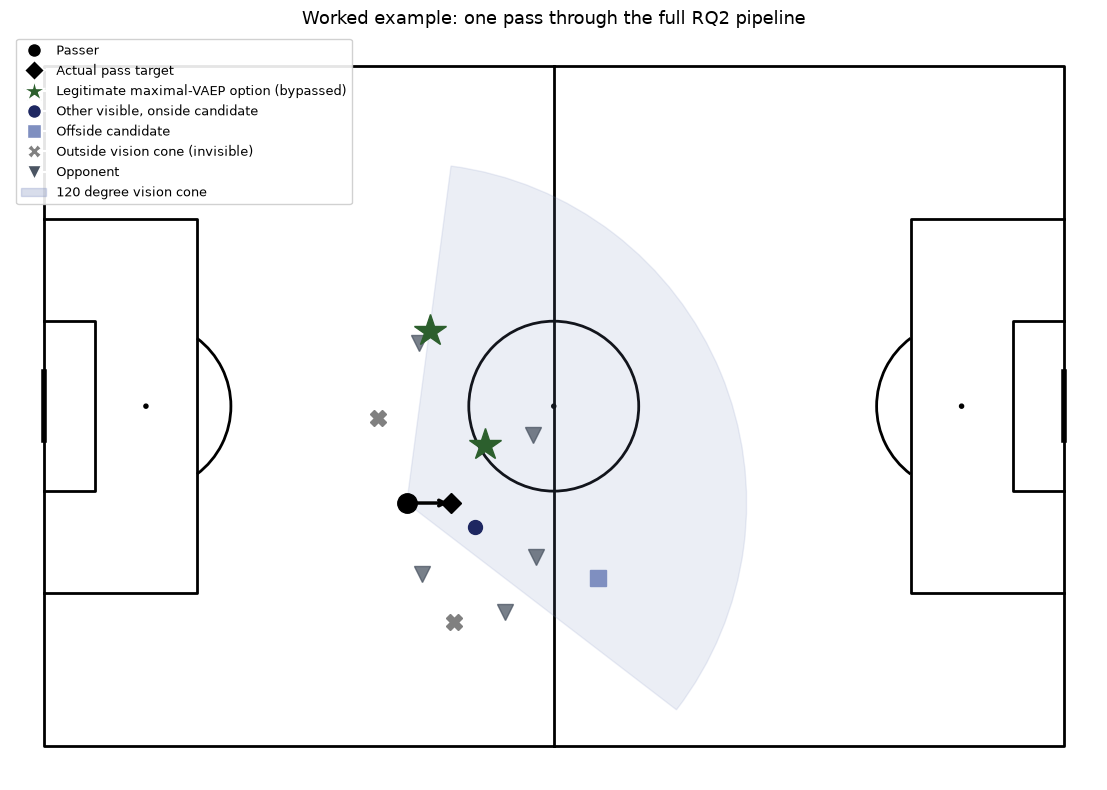

Bypassed option, distance to nearest defender: 1.85m, defenders nearby: 1, xP: 0.516


In [33]:
frame_at_example = cached_frames(str(example_match_id))
frame_rows_example = frame_at_example[frame_at_example['id'] == example_event_id]

opponents_at_example = frame_rows_example[frame_rows_example['teammate'] == False]

pitch = Pitch(pitch_type='statsbomb', line_color='black')
fig, ax = pitch.draw(figsize=(12, 8))

ax.plot(passer_loc[0], passer_loc[1], 'o', color='black', markersize=14, zorder=5)

angle_center = np.degrees(np.arctan2(passer_orientation[1], passer_orientation[0]))
cone = mpatches.Wedge(
    (passer_loc[0], passer_loc[1]), 40, angle_center - 60, angle_center + 60,
    color='#7F8FC0', alpha=0.15, zorder=1
)
ax.add_patch(cone)

for _, opp in opponents_at_example.iterrows():
    ox, oy = opp['location']
    marker = '^' if opp['keeper'] else 'v'
    ax.plot(ox, oy, marker, color='#4B5563', markersize=11, alpha=0.75, zorder=3)

for _, row in example_rows.iterrows():
    x, y = row['cand_x'], row['cand_y']
    if not row['visible']:
        ax.plot(x, y, 'X', color='grey', markersize=12, zorder=4)
    elif row['offside']:
        ax.plot(x, y, 's', color='#7F8FC0', markersize=12, zorder=4)
    elif row['legitimate_maximal_vaep']:
        ax.plot(x, y, '*', color='#2C5F2D', markersize=24, zorder=6)
    else:
        ax.plot(x, y, 'o', color='#1E2761', markersize=10, zorder=4)

ax.annotate('', xy=(real_end_x, real_end_y), xytext=(passer_loc[0], passer_loc[1]),
            arrowprops=dict(arrowstyle='->', color='black', lw=2.5))
ax.plot(real_end_x, real_end_y, 'D', color='black', markersize=10, zorder=5)

legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=10, label='Passer'),
    plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='black', markersize=10, label='Actual pass target'),
    plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='#2C5F2D', markersize=16,
               label='Legitimate maximal-VAEP option (bypassed)'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#1E2761', markersize=10,
               label='Other visible, onside candidate'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#7F8FC0', markersize=10, label='Offside candidate'),
    plt.Line2D([0], [0], marker='X', color='w', markerfacecolor='grey', markersize=10,
               label='Outside vision cone (invisible)'),
    plt.Line2D([0], [0], marker='v', color='w', markerfacecolor='#4B5563', markersize=10, label='Opponent'),
    mpatches.Patch(color='#7F8FC0', alpha=0.3, label='120 degree vision cone'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=9, framealpha=0.9)
ax.set_title('Worked example: one pass through the full RQ2 pipeline', fontsize=13)

fig.tight_layout()
save_fig(fig, 'rq2_worked_example_pitch.png')
plt.show()

star_row = example_rows[example_rows['legitimate_maximal_vaep']].iloc[0]
star_features = compute_xp_features(passer_loc, (star_row['cand_x'], star_row['cand_y']), frame_rows_example)
print(f"Bypassed option, distance to nearest defender: {star_features['nearest_defender_dist']:.2f}m, "
      f"defenders nearby: {star_features['defender_density']}, xP: {star_row['xp_value']:.3f}")

In [34]:
frame_at_example_full = cached_frames(str(example_match_id))
frame_rows_example = frame_at_example_full[frame_at_example_full['id'] == example_event_id]

opponents_check = frame_rows_example[frame_rows_example['teammate'] == False].copy()
opponents_check['x'] = opponents_check['location'].apply(lambda loc: loc[0])
opponents_check['y'] = opponents_check['location'].apply(lambda loc: loc[1])

square_row = example_rows[example_rows['offside'] == True].iloc[0]
attacking_toward_x_used = square_row['attacking_toward_x']

print(f"attacking_toward_x used for this event: {attacking_toward_x_used:.2f}")
print(f"keeper visible in this frame: {opponents_check['keeper'].any()}")
print("\nopponents sorted deepest first:")
print(opponents_check[['x', 'y', 'keeper']].sort_values('x', ascending=(attacking_toward_x_used <= 60)))

offside_line_check = compute_offside_line(frame_rows_example, attacking_toward_x_used)
print(f"\ncomputed offside line x: {offside_line_check:.2f}")
print(f"offside candidate (square) x: {square_row['cand_x']:.2f}")

attacking_toward_x used for this event: 116.86
keeper visible in this frame: False

opponents sorted deepest first:
               x          y  keeper
33722  57.930199  57.764999   False
33721  57.512529  43.346844   False
33720  54.318654  64.275574   False
33715  44.449219  59.751948   False
33714  44.171769  32.527117   False

computed offside line x: 57.93
offside candidate (square) x: 65.24


### Two more examples

The same pipeline is shown on two passes that look nothing alike. They are taken from different points in the pool of 6938 qualifying events, spread out rather than adjacent, so they are unlikely to come from the same match or passage of play. They are drawn and diagnosed exactly like the first example.

The second and third examples differ from the ones shown before the xT unit fix, because the pool of qualifying events changed slightly and the examples are picked by position in that pool. The first example is the same pass and is unchanged.

In [35]:
# second worked example, pulled from roughly a third of the way through the
# pool of good candidate events found above, so it is very unlikely to be
# from the same match or passage of play as the first example
idx_2 = int(len(good_event_ids) * 0.33) % len(good_event_ids)
example_match_id_2, example_event_id_2 = good_event_ids[idx_2]
print(f"Second example: match {example_match_id_2}, event {example_event_id_2}")

example_rows_2 = candidates_full[
    (candidates_full['match_id'] == example_match_id_2) &
    (candidates_full['original_event_id'] == example_event_id_2)
].copy()

m_events_example_2 = cached_events(str(example_match_id_2))
m_events_oriented_example_2 = add_orientation_vectors(m_events_example_2)
matching_event_2 = m_events_oriented_example_2[m_events_oriented_example_2['id'] == example_event_id_2].iloc[0]
passer_loc_2 = matching_event_2['location']
passer_orientation_2 = matching_event_2['orientation_vector']
# the real pass end from the StatsBomb event, in the same coordinates as the pitch and freeze frame
real_end_x_2, real_end_y_2 = matching_event_2['pass_end_location']

print(example_rows_2[['cand_x', 'cand_y', 'visible', 'offside', 'xp_value',
                       'maximal_vaep', 'legitimate_maximal_vaep']])


Second example: match 3857258, event 0f495bec-1905-46b9-a4e8-5dda61d19b8f
         cand_x   cand_y  visible offside  xp_value  maximal_vaep  \
213947  55.8555  50.7663    False   False  0.891226                False   
213948  65.4405  27.6761    False   False  0.686418                False   
213949  66.8943  75.4954    False   False  0.949724                False   
213950  69.5448  60.5042    False   False  0.938715                False   
213951  86.5246  13.6864     True   False  0.411224                 True   
213952  86.9963  83.0015    False   False  0.914094                 True   
213953  88.5549  59.8915     True   False  0.636679                 True   
213954  91.0834  44.8477     True   False  0.365031                 True   
213955  99.0185  47.6407     True    True  0.318875                 True   

        legitimate_maximal_vaep  
213947                           False  
213948                           False  
213949                           False  
213950         

saved ..\data\results\figures\rq2_worked_example_pitch_2.png


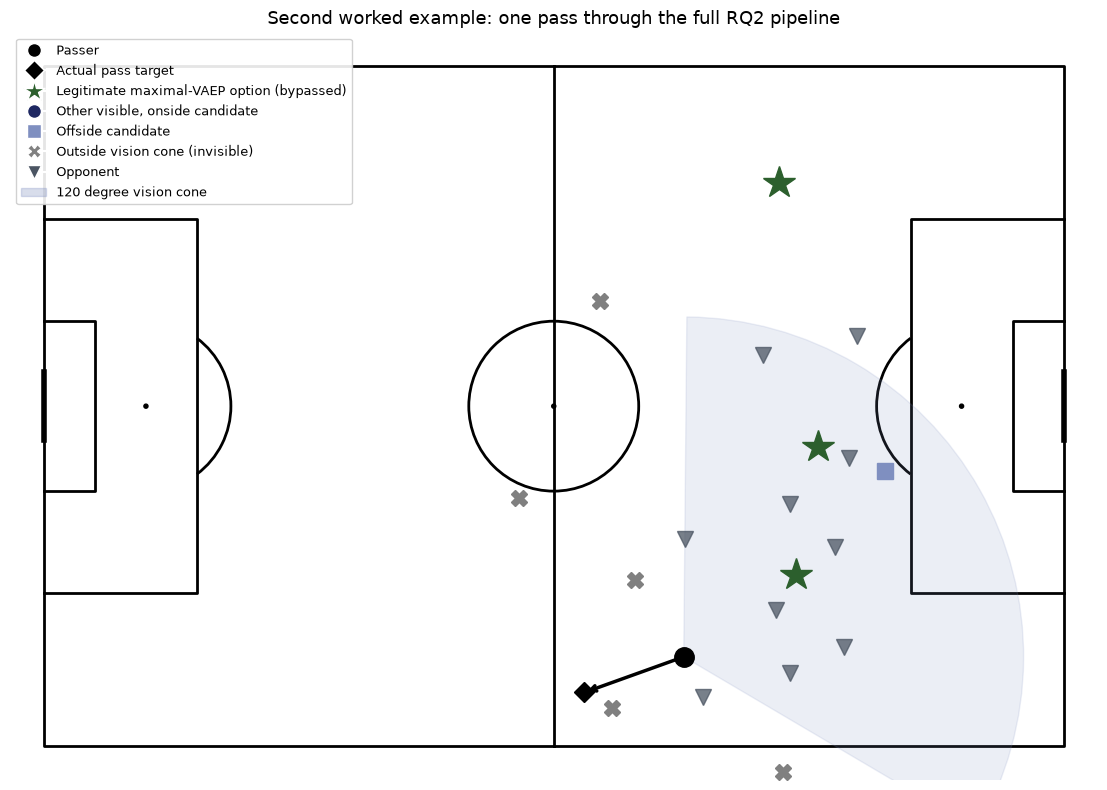

Bypassed option, distance to nearest defender: 20.27m, defenders nearby: 0, xP: 0.411


In [36]:
frame_at_example_2 = cached_frames(str(example_match_id_2))
frame_rows_example_2 = frame_at_example_2[frame_at_example_2['id'] == example_event_id_2]

opponents_at_example_2 = frame_rows_example_2[frame_rows_example_2['teammate'] == False]

pitch = Pitch(pitch_type='statsbomb', line_color='black')
fig, ax = pitch.draw(figsize=(12, 8))

ax.plot(passer_loc_2[0], passer_loc_2[1], 'o', color='black', markersize=14, zorder=5)

angle_center_2 = np.degrees(np.arctan2(passer_orientation_2[1], passer_orientation_2[0]))
cone_2 = mpatches.Wedge(
    (passer_loc_2[0], passer_loc_2[1]), 40, angle_center_2 - 60, angle_center_2 + 60,
    color='#7F8FC0', alpha=0.15, zorder=1
)
ax.add_patch(cone_2)

for _, opp in opponents_at_example_2.iterrows():
    ox, oy = opp['location']
    marker = '^' if opp['keeper'] else 'v'
    ax.plot(ox, oy, marker, color='#4B5563', markersize=11, alpha=0.75, zorder=3)

for _, row in example_rows_2.iterrows():
    x, y = row['cand_x'], row['cand_y']
    if not row['visible']:
        ax.plot(x, y, 'X', color='grey', markersize=12, zorder=4)
    elif row['offside']:
        ax.plot(x, y, 's', color='#7F8FC0', markersize=12, zorder=4)
    elif row['legitimate_maximal_vaep']:
        ax.plot(x, y, '*', color='#2C5F2D', markersize=24, zorder=6)
    else:
        ax.plot(x, y, 'o', color='#1E2761', markersize=10, zorder=4)

ax.annotate('', xy=(real_end_x_2, real_end_y_2), xytext=(passer_loc_2[0], passer_loc_2[1]),
            arrowprops=dict(arrowstyle='->', color='black', lw=2.5))
ax.plot(real_end_x_2, real_end_y_2, 'D', color='black', markersize=10, zorder=5)

legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=10, label='Passer'),
    plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='black', markersize=10, label='Actual pass target'),
    plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='#2C5F2D', markersize=16,
               label='Legitimate maximal-VAEP option (bypassed)'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#1E2761', markersize=10,
               label='Other visible, onside candidate'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#7F8FC0', markersize=10, label='Offside candidate'),
    plt.Line2D([0], [0], marker='X', color='w', markerfacecolor='grey', markersize=10,
               label='Outside vision cone (invisible)'),
    plt.Line2D([0], [0], marker='v', color='w', markerfacecolor='#4B5563', markersize=10, label='Opponent'),
    mpatches.Patch(color='#7F8FC0', alpha=0.3, label='120 degree vision cone'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=9, framealpha=0.9)
ax.set_title('Second worked example: one pass through the full RQ2 pipeline', fontsize=13)

fig.tight_layout()
save_fig(fig, 'rq2_worked_example_pitch_2.png')
plt.show()

star_row_2 = example_rows_2[example_rows_2['legitimate_maximal_vaep']].iloc[0]
star_features_2 = compute_xp_features(passer_loc_2, (star_row_2['cand_x'], star_row_2['cand_y']), frame_rows_example_2)
print(f"Bypassed option, distance to nearest defender: {star_features_2['nearest_defender_dist']:.2f}m, "
      f"defenders nearby: {star_features_2['defender_density']}, xP: {star_row_2['xp_value']:.3f}")


In [37]:
frame_at_example_full_2 = cached_frames(str(example_match_id_2))
frame_rows_example_2 = frame_at_example_full_2[frame_at_example_full_2['id'] == example_event_id_2]

opponents_check_2 = frame_rows_example_2[frame_rows_example_2['teammate'] == False].copy()
opponents_check_2['x'] = opponents_check_2['location'].apply(lambda loc: loc[0])
opponents_check_2['y'] = opponents_check_2['location'].apply(lambda loc: loc[1])

offside_rows_2 = example_rows_2[example_rows_2['offside'] == True]
if len(offside_rows_2) > 0:
    square_row_2 = offside_rows_2.iloc[0]
    attacking_toward_x_used_2 = square_row_2['attacking_toward_x']

    print(f"attacking_toward_x used for this event: {attacking_toward_x_used_2:.2f}")
    print(f"keeper visible in this frame: {opponents_check_2['keeper'].any()}")
    print("\nopponents sorted deepest first:")
    print(opponents_check_2[['x', 'y', 'keeper']].sort_values('x', ascending=(attacking_toward_x_used_2 <= 60)))

    offside_line_check_2 = compute_offside_line(frame_rows_example_2, attacking_toward_x_used_2)
    print(f"\ncomputed offside line x: {offside_line_check_2:.2f}")
    print(f"offside candidate (square) x: {square_row_2['cand_x']:.2f}")
else:
    print("No offside candidate present in this particular example, skipping the offside-line diagnostic.")


attacking_toward_x used for this event: 116.23
keeper visible in this frame: False

opponents sorted deepest first:
               x          y  keeper
23740  95.650474  31.789763   False
23739  94.706676  46.156066   False
23738  94.176572  68.365382   False
23737  93.066680  56.593228   False
23734  87.843824  71.431282   False
23733  87.809638  51.458470   False
23730  86.186901  64.011771   False
23729  84.572616  33.939763   False
23728  77.591490  74.203979   False
23727  75.446749  55.686226   False

computed offside line x: 95.65
offside candidate (square) x: 99.02


### Third example

In [38]:
# third worked example, from roughly two-thirds of the way through the pool
idx_3 = int(len(good_event_ids) * 0.66) % len(good_event_ids)
example_match_id_3, example_event_id_3 = good_event_ids[idx_3]
print(f"Third example: match {example_match_id_3}, event {example_event_id_3}")

example_rows_3 = candidates_full[
    (candidates_full['match_id'] == example_match_id_3) &
    (candidates_full['original_event_id'] == example_event_id_3)
].copy()

m_events_example_3 = cached_events(str(example_match_id_3))
m_events_oriented_example_3 = add_orientation_vectors(m_events_example_3)
matching_event_3 = m_events_oriented_example_3[m_events_oriented_example_3['id'] == example_event_id_3].iloc[0]
passer_loc_3 = matching_event_3['location']
passer_orientation_3 = matching_event_3['orientation_vector']
# the real pass end from the StatsBomb event, in the same coordinates as the pitch and freeze frame
real_end_x_3, real_end_y_3 = matching_event_3['pass_end_location']

print(example_rows_3[['cand_x', 'cand_y', 'visible', 'offside', 'xp_value',
                       'maximal_vaep', 'legitimate_maximal_vaep']])


Third example: match 3869685, event aa3fc5d8-d37c-458b-9982-f7147aaddc28
         cand_x   cand_y  visible offside  xp_value  maximal_vaep  \
437815  52.7454  34.4211     True   False  0.877747                 True   
437816  53.0545  77.7983    False   False  0.798872                False   
437817  62.5020  56.6092     True   False  0.716602                 True   
437818  70.9797  17.8643     True   False  0.520934                False   
437819  75.4158  60.1482     True   False  0.484959                 True   
437820  85.9478  25.7294     True    True  0.201999                 True   

        legitimate_maximal_vaep  
437815                            True  
437816                           False  
437817                            True  
437818                           False  
437819                            True  
437820                           False  


saved ..\data\results\figures\rq2_worked_example_pitch_3.png


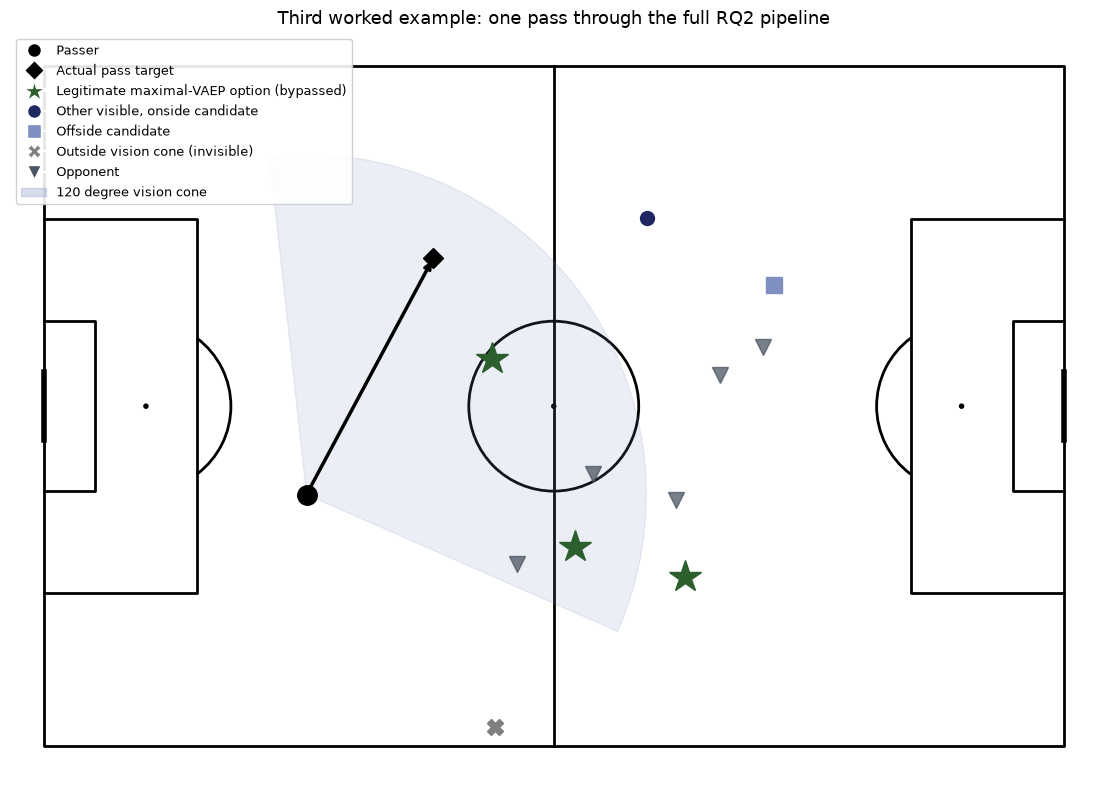

Bypassed option, distance to nearest defender: 17.98m, defenders nearby: 0, xP: 0.878


In [39]:
frame_at_example_3 = cached_frames(str(example_match_id_3))
frame_rows_example_3 = frame_at_example_3[frame_at_example_3['id'] == example_event_id_3]

opponents_at_example_3 = frame_rows_example_3[frame_rows_example_3['teammate'] == False]

pitch = Pitch(pitch_type='statsbomb', line_color='black')
fig, ax = pitch.draw(figsize=(12, 8))

ax.plot(passer_loc_3[0], passer_loc_3[1], 'o', color='black', markersize=14, zorder=5)

angle_center_3 = np.degrees(np.arctan2(passer_orientation_3[1], passer_orientation_3[0]))
cone_3 = mpatches.Wedge(
    (passer_loc_3[0], passer_loc_3[1]), 40, angle_center_3 - 60, angle_center_3 + 60,
    color='#7F8FC0', alpha=0.15, zorder=1
)
ax.add_patch(cone_3)

for _, opp in opponents_at_example_3.iterrows():
    ox, oy = opp['location']
    marker = '^' if opp['keeper'] else 'v'
    ax.plot(ox, oy, marker, color='#4B5563', markersize=11, alpha=0.75, zorder=3)

for _, row in example_rows_3.iterrows():
    x, y = row['cand_x'], row['cand_y']
    if not row['visible']:
        ax.plot(x, y, 'X', color='grey', markersize=12, zorder=4)
    elif row['offside']:
        ax.plot(x, y, 's', color='#7F8FC0', markersize=12, zorder=4)
    elif row['legitimate_maximal_vaep']:
        ax.plot(x, y, '*', color='#2C5F2D', markersize=24, zorder=6)
    else:
        ax.plot(x, y, 'o', color='#1E2761', markersize=10, zorder=4)

ax.annotate('', xy=(real_end_x_3, real_end_y_3), xytext=(passer_loc_3[0], passer_loc_3[1]),
            arrowprops=dict(arrowstyle='->', color='black', lw=2.5))
ax.plot(real_end_x_3, real_end_y_3, 'D', color='black', markersize=10, zorder=5)

legend_elements = [
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='black', markersize=10, label='Passer'),
    plt.Line2D([0], [0], marker='D', color='w', markerfacecolor='black', markersize=10, label='Actual pass target'),
    plt.Line2D([0], [0], marker='*', color='w', markerfacecolor='#2C5F2D', markersize=16,
               label='Legitimate maximal-VAEP option (bypassed)'),
    plt.Line2D([0], [0], marker='o', color='w', markerfacecolor='#1E2761', markersize=10,
               label='Other visible, onside candidate'),
    plt.Line2D([0], [0], marker='s', color='w', markerfacecolor='#7F8FC0', markersize=10, label='Offside candidate'),
    plt.Line2D([0], [0], marker='X', color='w', markerfacecolor='grey', markersize=10,
               label='Outside vision cone (invisible)'),
    plt.Line2D([0], [0], marker='v', color='w', markerfacecolor='#4B5563', markersize=10, label='Opponent'),
    mpatches.Patch(color='#7F8FC0', alpha=0.3, label='120 degree vision cone'),
]
ax.legend(handles=legend_elements, loc='upper left', fontsize=9, framealpha=0.9)
ax.set_title('Third worked example: one pass through the full RQ2 pipeline', fontsize=13)

fig.tight_layout()
save_fig(fig, 'rq2_worked_example_pitch_3.png')
plt.show()

star_row_3 = example_rows_3[example_rows_3['legitimate_maximal_vaep']].iloc[0]
star_features_3 = compute_xp_features(passer_loc_3, (star_row_3['cand_x'], star_row_3['cand_y']), frame_rows_example_3)
print(f"Bypassed option, distance to nearest defender: {star_features_3['nearest_defender_dist']:.2f}m, "
      f"defenders nearby: {star_features_3['defender_density']}, xP: {star_row_3['xp_value']:.3f}")


In [40]:
frame_at_example_full_3 = cached_frames(str(example_match_id_3))
frame_rows_example_3 = frame_at_example_full_3[frame_at_example_full_3['id'] == example_event_id_3]

opponents_check_3 = frame_rows_example_3[frame_rows_example_3['teammate'] == False].copy()
opponents_check_3['x'] = opponents_check_3['location'].apply(lambda loc: loc[0])
opponents_check_3['y'] = opponents_check_3['location'].apply(lambda loc: loc[1])

offside_rows_3 = example_rows_3[example_rows_3['offside'] == True]
if len(offside_rows_3) > 0:
    square_row_3 = offside_rows_3.iloc[0]
    attacking_toward_x_used_3 = square_row_3['attacking_toward_x']

    print(f"attacking_toward_x used for this event: {attacking_toward_x_used_3:.2f}")
    print(f"keeper visible in this frame: {opponents_check_3['keeper'].any()}")
    print("\nopponents sorted deepest first:")
    print(opponents_check_3[['x', 'y', 'keeper']].sort_values('x', ascending=(attacking_toward_x_used_3 <= 60)))

    offside_line_check_3 = compute_offside_line(frame_rows_example_3, attacking_toward_x_used_3)
    print(f"\ncomputed offside line x: {offside_line_check_3:.2f}")
    print(f"offside candidate (square) x: {square_row_3['cand_x']:.2f}")
else:
    print("No offside candidate present in this particular example, skipping the offside-line diagnostic.")


attacking_toward_x used for this event: 116.23
keeper visible in this frame: False

opponents sorted deepest first:
               x          y  keeper
31849  84.606038  33.018937   False
31848  79.566887  36.331385   False
31846  74.377090  51.082443   False
31844  64.586962  47.955608   False
31842  55.635093  58.567425   False

computed offside line x: 84.61
offside candidate (square) x: 85.95


## 8. Where bypassed maximal-VAEP options happen on the pitch

Across all 98652 passes, where on the pitch a legitimate maximal-VAEP option was available and bypassed, by the passer's location.

saved ..\data\results\figures\rq2_bias_heatmap.png


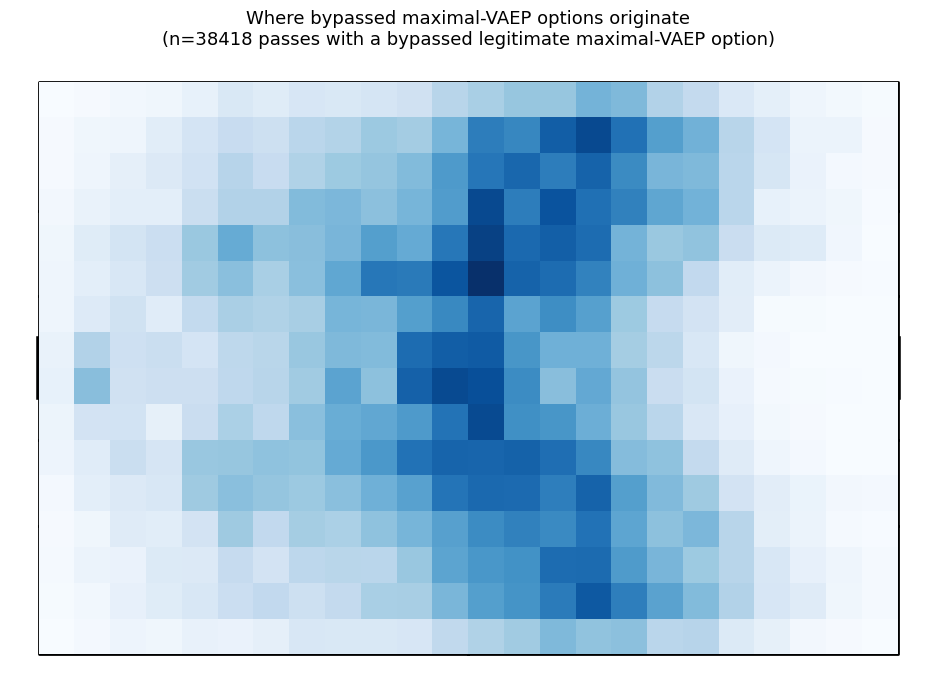

In [41]:
pass_level_full = candidates_full.groupby(['match_id', 'original_event_id']).agg(
    had_legit_option=('legitimate_maximal_vaep', 'any'),
    passer_x=('passer_location', lambda s: s.iloc[0][0]),
    passer_y=('passer_location', lambda s: s.iloc[0][1]),
).reset_index()

bypassed = pass_level_full[pass_level_full['had_legit_option']]

pitch = Pitch(pitch_type='statsbomb', line_color='black')
fig, ax = pitch.draw(figsize=(10, 7))
bin_statistic = pitch.bin_statistic(bypassed['passer_x'], bypassed['passer_y'], statistic='count', bins=(24, 16))
pitch.heatmap(bin_statistic, ax=ax, cmap='Blues', edgecolors='none')
ax.set_title(f'Where bypassed maximal-VAEP options originate\n(n={len(bypassed)} passes with a bypassed legitimate maximal-VAEP option)',
             fontsize=13)

fig.tight_layout()
save_fig(fig, 'rq2_bias_heatmap.png')
plt.show()

**What this shows**

**The map is already oriented by attacking direction.** StatsBomb records every event from the point of view of the team in possession, attacking toward x = 120, which is also why the `attacking_toward_x` values in the worked examples all sit close to 120. The left edge is the passer's own goal line and the right edge is the goal they are attacking.

**Bypassed options concentrate around the halfway line.** They cluster in a band around halfway and the first part of the opponent's half, across most of the width of the pitch, and thin out toward both penalty areas. This is where teams build possession, with several teammates ahead of the passer and time on the ball, so it is where a maximal-VAEP option is most often available and left unused. Deep in the attacking third, maximal-VAEP options are naturally scarcer; deep in the passer's own half, the safer pass is often the sensible one.

In [42]:
cols = {
    "xp_value": "xP (completion probability)",
    "xt_origin": "xT at passer's location",
    "xt_target": "xT at candidate's location",
    "candidate_value": "VAEP of the candidate pass (hypothetical)",
    "real_value": "VAEP of the pass actually made",
}

for col, label in cols.items():
    s = candidates_full[col].dropna()
    print(f"{label} [{col}]")
    print(f"  min={s.min():.4f}  max={s.max():.4f}  mean={s.mean():.4f}  median={s.median():.4f}")
    print(f"  1st pct={s.quantile(0.01):.4f}  99th pct={s.quantile(0.99):.4f}")
    print()

# the xT delta actually used by the maximal-VAEP check
xt_delta = candidates_full["xt_target"] - candidates_full["xt_origin"]
print("xT delta (target - origin)")
print(f"  min={xt_delta.min():.4f}  max={xt_delta.max():.4f}  mean={xt_delta.mean():.4f}")

# the VAEP delta actually used by the maximal-VAEP check
vaep_delta = candidates_full["candidate_value"] - candidates_full["real_value"]
print("VAEP delta (candidate - real pass)")
print(f"  min={vaep_delta.min():.4f}  max={vaep_delta.max():.4f}  mean={vaep_delta.mean():.4f}")

xP (completion probability) [xp_value]
  min=0.0000  max=0.9998  mean=0.6876  median=0.7568
  1st pct=0.0686  99th pct=0.9604

xT at passer's location [xt_origin]
  min=0.0056  max=0.2798  mean=0.0162  median=0.0144
  1st pct=0.0081  99th pct=0.0431

xT at candidate's location [xt_target]
  min=0.0053  max=0.3322  mean=0.0207  median=0.0162
  1st pct=0.0087  99th pct=0.1067

VAEP of the candidate pass (hypothetical) [candidate_value]
  min=-0.9974  max=0.9853  mean=0.0003  median=0.0000
  1st pct=-0.0243  99th pct=0.0216

VAEP of the pass actually made [real_value]
  min=-0.9973  max=0.9368  mean=0.0000  median=-0.0002
  1st pct=-0.0231  99th pct=0.0226

xT delta (target - origin)
  min=-0.2440  max=0.3010  mean=0.0044
VAEP delta (candidate - real pass)
  min=-0.6919  max=0.9926  mean=0.0003


In [43]:
import os

os.makedirs('../data/results', exist_ok=True)
candidates_full.to_pickle('../data/results/candidates_full.pkl')
print(f"Saved candidates_full: {len(candidates_full)} rows -> ../data/results/candidates_full.pkl")

Saved candidates_full: 664518 rows -> ../data/results/candidates_full.pkl


## 9. Figures

These cells make the summary charts in the shared colour scheme, from this notebook's own results, and save them to `../data/results/figures/`. They do not change any result.

This cell reads the saved pass-level flags, so it only needs the imports at the top of the notebook (it loads the match list with statsbombpy to label the competitions).

In [44]:
import numpy as np
import matplotlib.pyplot as plt
from pathlib import Path

# shared colours and style for the figures below
NAVY, GREEN, GREY, LIGHT, TXT = '#1E2761', '#2C5F2D', '#9AA0A6', '#7F8FC0', '#1B1B1F'
plt.rcParams.update({'font.family': 'DejaVu Sans', 'font.size': 12, 'axes.spines.top': False,
                     'axes.spines.right': False, 'axes.edgecolor': '#6B7280', 'axes.labelcolor': TXT,
                     'xtick.color': TXT, 'ytick.color': '#6B7280'})


def deck_bars(ax, labels, vals, colours, lo=None, hi=None, fmt='{:.1f}%', ymax=None, off=1.0):
    """Bar chart in the shared style, with optional confidence intervals and value labels."""
    x = np.arange(len(vals))
    ax.bar(x, vals, color=colours, width=0.62)
    if lo is not None:
        ax.errorbar(x, vals, yerr=[np.subtract(vals, lo), np.subtract(hi, vals)],
                    fmt='none', ecolor=TXT, capsize=5, lw=1.2)
    for i, v in enumerate(vals):
        top = hi[i] if hi is not None else v
        ax.text(i, top + off, fmt.format(v), ha='center', va='bottom', fontsize=13, fontweight='bold', color=TXT)
    ax.set_xticks(x)
    ax.set_xticklabels(labels)
    if ymax:
        ax.set_ylim(0, ymax)


saved ..\data\results\figures\rq2_headline_rate.png


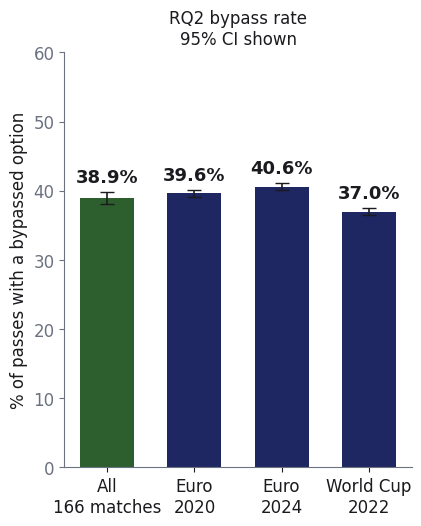

saved ..\data\results\figures\rq2_headline_by_competition.png


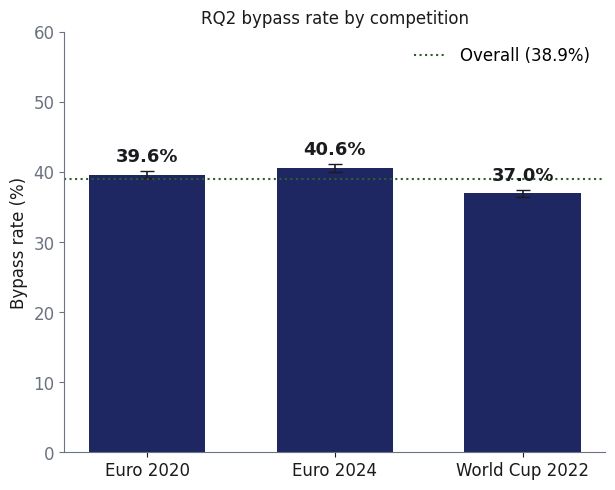

overall [38.9 38.1 39.8] by competition [39.6 40.6 37. ]


In [45]:
# RQ2 headline chart and competition chart, from the saved pass-level flags.
# Needs only the imports at the top of this notebook.
pl = pd.read_pickle('../data/results/rq2_bypass_rate.pkl')
pl['match_id'] = pl['match_id'].astype(str)
comp_of = {}
for name, cid, sid in [('Euro 2024', 55, 282), ('Euro 2020', 55, 43), ('World Cup 2022', 43, 106)]:
    for mid in sb.matches(competition_id=cid, season_id=sid)['match_id']:
        comp_of[str(mid)] = name
pl['competition'] = pl['match_id'].map(comp_of)

# overall rate with a 95% interval from resampling whole matches (same method as the option-pool cell)
per_match = pl.groupby('match_id')['had_legit_option'].agg(['sum', 'count'])
idx = np.random.default_rng(0).integers(0, len(per_match), size=(5000, len(per_match)))
boot = per_match['sum'].to_numpy()[idx].sum(axis=1) / per_match['count'].to_numpy()[idx].sum(axis=1)
overall = [100 * pl['had_legit_option'].mean(), 100 * np.percentile(boot, 2.5), 100 * np.percentile(boot, 97.5)]

# per competition, with Wilson intervals (same as the competition cell)
def wilson(k, n, z=1.96):
    p = k / n
    centre = (p + z**2 / (2 * n)) / (1 + z**2 / n)
    half = z * np.sqrt(p * (1 - p) / n + z**2 / (4 * n**2)) / (1 + z**2 / n)
    return centre - half, centre + half

comps = ['Euro 2020', 'Euro 2024', 'World Cup 2022']
cv, clo, chi = [], [], []
for c in comps:
    g = pl.loc[pl['competition'] == c, 'had_legit_option']
    lo, hi = wilson(g.sum(), len(g))
    cv.append(100 * g.mean()); clo.append(100 * lo); chi.append(100 * hi)

fig, ax = plt.subplots(figsize=(4.48, 5.39))
deck_bars(ax, ['All\n166 matches', 'Euro\n2020', 'Euro\n2024', 'World Cup\n2022'],
          [overall[0]] + cv, [GREEN, NAVY, NAVY, NAVY],
          [overall[1]] + clo, [overall[2]] + chi, ymax=60, off=0.8)
ax.set_ylabel('% of passes with a bypassed option')
ax.set_title('RQ2 bypass rate\n95% CI shown', fontsize=12, color=TXT)
save_fig(fig, 'rq2_headline_rate.png')
plt.show()
fig, ax = plt.subplots(figsize=(6.98, 5.46))
deck_bars(ax, comps, cv, [NAVY] * 3, clo, chi, ymax=60, off=0.8)
ax.axhline(overall[0], ls=':', color=GREEN, lw=1.5, label=f'Overall ({overall[0]:.1f}%)')
ax.legend(frameon=False, loc='upper right')
ax.set_ylabel('Bypass rate (%)')
ax.set_title('RQ2 bypass rate by competition', fontsize=12, color=TXT)
save_fig(fig, 'rq2_headline_by_competition.png')
plt.show()
print('overall', np.round(overall, 1), 'by competition', np.round(cv, 1))

## Summary

**RQ2 finding.** Among options the passer could see, were onside and could realistically complete, a better maximal-VAEP option was bypassed in **38.9 percent** of 98652 passes (95 percent CI 38.1 to 39.8, resampling matches). This supports H2: the bias is not explained by perception or legality alone.

**The filters.**

- The offside rule uses the deepest visible outfield defender when the goalkeeper is off camera, and exempts the passer's own half; 3.5 percent of candidates are offside.
- xP (AUC 0.823, cross-validated 0.827) removes passes below a 5 percent completion chance. A gradient boosting model would change only 0.67 percent of those decisions.
- xT is computed in SPADL metres after the unit fix.

**The result is robust.** The rate is 37.0 to 40.6 percent in each of the three tournaments. About one legitimate option in ten is not ahead of the passer; requiring the bypassed option to be ahead of the passer gives 36.2 percent, and at least 10 yards ahead 26.8 percent.

**Perception matters for RQ2 too.** Counting every teammate, as an omniscient model would, raises the rate to 74.2 percent. Almost half of those flags (47.6 percent) come only from teammates outside the vision cone.

**Where it happens.** Bypassed options are most common around the halfway line and the start of the opponent's half.

Risk and context are tested in `03_layer2_risk_and_context.ipynb`. The flag is compared with PFF analysts' better-option labels in `15_layer3_pff_better_options.ipynb`.